In [1]:
#PREPROCESSING + LR FINAL WORKING R2= 0.7
import numpy as np
import pandas as pd
import re
from collections import Counter
from textblob import TextBlob
from scipy.sparse import dok_matrix, csr_matrix
from scipy.sparse.linalg import svds

# -----------------------
# Reproducibility
# -----------------------
np.random.seed(42)

# ================================================================
# LOAD TRAIN + TEST
# ================================================================
train = pd.read_csv("train.csv")
test  = pd.read_csv("test.csv")

# ================================================================
# 1. DROP NAs IN TRAIN ONLY  (NO LEAKAGE)
# ================================================================
required_cols = ["budget","revenue","runtime","popularity",
                 "vote_average","vote_count","overview","release_date"]

train = train.dropna(subset=required_cols).reset_index(drop=True)

# Keep test structure, but don't use test stats
test = test.fillna("")

# Combine only for feature extraction convenience (not for computing stats)
df_all = pd.concat([train, test], ignore_index=True)
train_len = len(train)

# ================================================================
# 2. BASIC TEXT CLEANING
# ================================================================
for col in ["title","overview","tagline","genres"]:
    df_all[col] = df_all[col].fillna("").astype(str)

# ================================================================
# 3. GENRE FIX (use df_all, then split)
# ================================================================
def extract_genre(x):
    if not isinstance(x, str) or x.strip() == "":
        return "Unknown"
    return x.split("-")[0].strip()

df_all["main_genre"] = df_all["genres"].apply(extract_genre)

# ================================================================
# 4. NUMERIC FIX (coerce then fill zeros for test; train has full rows)
# ================================================================
numeric_cols = ["budget","revenue","runtime","popularity",
                "vote_average","vote_count"]

for col in numeric_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce").fillna(0.0)

# ================================================================
# 5. DATE → YEAR
# ================================================================
df_all["release_date"] = pd.to_datetime(df_all["release_date"], errors="coerce")
# for missing years, use mode of available years in df_all (safe fallback)
available_years = df_all["release_date"].dt.year.dropna()
fill_year = int(available_years.mode().iloc[0]) if not available_years.empty else 2000
df_all["release_year"] = df_all["release_date"].dt.year.fillna(fill_year).astype(int)

# ================================================================
# 6. TEXT FEATURES (on overview)
# ================================================================
def word_count(s): 
    s = str(s)
    return len(s.split())

def avg_word_len(s):
    s = str(s)
    w = s.split()
    return np.mean([len(i) for i in w]) if w else 0.0

def sentiment_polarity(s):
    try:
        return float(TextBlob(str(s)).sentiment.polarity)
    except Exception:
        return 0.0

df_all["word_count"] = df_all["overview"].apply(word_count)
df_all["avg_word_length"] = df_all["overview"].apply(avg_word_len)
df_all["sentiment"] = df_all["overview"].apply(sentiment_polarity)

# ================================================================
# 7. SPLIT BACK INTO TRAIN / TEST
# ================================================================
df_train = df_all.iloc[:train_len].reset_index(drop=True)
df_test  = df_all.iloc[train_len:].reset_index(drop=True)

# Targets
y_revenue_train = df_train["revenue"].astype(np.float32).reset_index(drop=True)
y_genre_train = df_train["main_genre"].reset_index(drop=True)

# ================================================================
# 8. MANUAL NORMALIZATION (use train stats only)
# ================================================================
scale_cols = ["budget","runtime","popularity","vote_average","vote_count",
              "release_year","word_count","avg_word_length","sentiment"]

scaler_mean = df_train[scale_cols].mean()
scaler_std  = df_train[scale_cols].std().replace(0, 1.0)

X_num_train = (df_train[scale_cols] - scaler_mean) / scaler_std
X_num_test  = (df_test[scale_cols]  - scaler_mean) / scaler_std

# Convert numeric to numpy float32 arrays
num_train_np = X_num_train.to_numpy(dtype=np.float32)
num_test_np  = X_num_test.to_numpy(dtype=np.float32)

# ================================================================
# 9. TF-IDF (train ONLY builds vocab) - sparse dok -> csr
# ================================================================
def tokenize(text):
    return re.findall(r"[A-Za-z]+", str(text).lower())

# Build vocabulary from train only
train_tokens = df_train["overview"].apply(tokenize)
word_freq = Counter()
for tokens in train_tokens:
    word_freq.update(tokens)

max_features = 5000
vocab = [w for w, _ in word_freq.most_common(max_features)]
vocab_idx = {w: i for i, w in enumerate(vocab)}

# Compute document frequency (df) on train
N_train = len(df_train)
df_count = np.zeros(len(vocab), dtype=np.float32)
for tokens in train_tokens:
    for u in set(tokens):
        if u in vocab_idx:
            df_count[vocab_idx[u]] += 1.0

# IDF (smooth + 1)
idf = np.log((N_train + 1.0) / (df_count + 1.0)).astype(np.float32) + 1.0

# Build sparse TF-IDF for train (dok -> csr)
tfidf_train_dok = dok_matrix((len(df_train), len(vocab)), dtype=np.float32)
for i, tokens in enumerate(train_tokens):
    if not tokens:
        continue
    cnt = Counter(tokens)
    tot = len(tokens)
    for tok, c in cnt.items():
        j = vocab_idx.get(tok)
        if j is not None:
            tfidf_train_dok[i, j] = (c / tot) * idf[j]
tfidf_train_csr = tfidf_train_dok.tocsr()

# Build sparse TF-IDF for test using same vocab & idf
test_tokens = df_test["overview"].apply(tokenize)
tfidf_test_dok = dok_matrix((len(df_test), len(vocab)), dtype=np.float32)
for i, tokens in enumerate(test_tokens):
    if not tokens:
        continue
    cnt = Counter(tokens)
    tot = len(tokens)
    for tok, c in cnt.items():
        j = vocab_idx.get(tok)
        if j is not None:
            tfidf_test_dok[i, j] = (c / tot) * idf[j]
tfidf_test_csr = tfidf_test_dok.tocsr()

# ================================================================
# 10. DIMENSIONALITY REDUCTION: sparse SVD using scipy.sparse.linalg.svds
#     -> returns U (n x k), s (k,), Vt (k x d)
# ================================================================
k = 200  # target components; adjust if you need fewer/more
# If k >= number of features, skip SVD
if k >= tfidf_train_csr.shape[1]:
    # no reduction, use full tfidf (may be heavy)
    tfidf_train_reduced = tfidf_train_csr.toarray().astype(np.float32)
    tfidf_test_reduced  = tfidf_test_csr.toarray().astype(np.float32)
else:
    # compute top-k SVD on sparse matrix
    # svds returns singular vectors for largest singular values when which='LM' (default)
    U, s, Vt = svds(tfidf_train_csr, k=k)
    # svds returns in ascending order of singular values; reverse to descending
    idx_desc = np.argsort(s)[::-1]
    s = s[idx_desc].astype(np.float32)
    U = U[:, idx_desc].astype(np.float32)     # n_train x k
    Vt = Vt[idx_desc, :].astype(np.float32)   # k x d

    # Train reduced features: U * S
    tfidf_train_reduced = U * s[np.newaxis, :]   # broadcast multiply -> n_train x k

    # Test reduced features: project test TF-IDF onto V (V = Vt.T)
    # tfidf_test_csr (n_test x d) dot Vt.T (d x k) -> n_test x k
    tfidf_test_reduced = (tfidf_test_csr @ Vt.T).astype(np.float32)

# ================================================================
# 11. FINAL NUMPY FEATURE MATRICES (concatenate numeric + tfidf_svd)
# ================================================================
# Ensure shapes align
assert num_train_np.shape[0] == tfidf_train_reduced.shape[0]
assert num_test_np.shape[0]  == tfidf_test_reduced.shape[0]

X_train_np = np.concatenate([num_train_np, tfidf_train_reduced], axis=1).astype(np.float32)
X_test_np  = np.concatenate([num_test_np,  tfidf_test_reduced], axis=1).astype(np.float32)

y_train_np = y_revenue_train.to_numpy(dtype=np.float32)

print("Shapes:")
print("X_train_np:", X_train_np.shape)
print("X_test_np :", X_test_np.shape)
print("y_train_np:", y_train_np.shape)

# ================================================================
# 12. LABEL ENCODE GENRES (train only)
# ================================================================
genre_list = df_train["main_genre"].unique().tolist()
genre_to_idx = {g: i for i, g in enumerate(genre_list)}
y_genre_encoded_train = df_train["main_genre"].map(genre_to_idx).astype(int).to_numpy()

# ================================================================
# 13. Simple Linear Regression (scratch) - gradient descent
# ================================================================
class LinearRegressionScratch:
    def __init__(self, lr=0.001, epochs=2000, verbose=False):
        self.lr = lr
        self.epochs = epochs
        self.verbose = verbose

    def fit(self, X, y):
        n, d = X.shape
        # initialize small random weights for symmetry breaking
        rng = np.random.RandomState(42)
        self.w = rng.normal(scale=0.01, size=(d,)).astype(np.float32)
        self.b = 0.0
        for ep in range(self.epochs):
            y_pred = X.dot(self.w) + self.b
            err = y_pred - y
            dw = (1.0 / n) * (X.T.dot(err))
            db = (1.0 / n) * np.sum(err)
            self.w -= self.lr * dw
            self.b -= self.lr * db
            if self.verbose and (ep % 200 == 0):
                mse = np.mean(err**2)
                print(f"epoch {ep} mse={mse:.6f}")

    def predict(self, X):
        return X.dot(self.w) + self.b

# Metrics
def MAE(y, yhat): return np.mean(np.abs(y - yhat))
def MSE(y, yhat): return np.mean((y - yhat)**2)
def RMSE(y, yhat): return np.sqrt(MSE(y, yhat))
def R2(y, yhat):
    ss_res = np.sum((y - yhat)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1.0 - ss_res / ss_tot if ss_tot != 0 else 0.0

# Train & evaluate on training set (to reproduce your earlier R2 check)
lr_model = LinearRegressionScratch(lr=0.001, epochs=2000, verbose=True)
lr_model.fit(X_train_np, y_train_np)
pred_train = lr_model.predict(X_train_np)

print("\nTraining metrics:")
print("MAE:", MAE(y_train_np, pred_train))
print("RMSE:", RMSE(y_train_np, pred_train))
print("R2:", R2(y_train_np, pred_train))

# If you want a quick validation split to approximate generalization:
hold = int(0.8 * X_train_np.shape[0])
X_tr, X_val = X_train_np[:hold], X_train_np[hold:]
y_tr, y_val = y_train_np[:hold], y_train_np[hold:]

lr_small = LinearRegressionScratch(lr=0.001, epochs=2000)
lr_small.fit(X_tr, y_tr)
pred_val = lr_small.predict(X_val)
print("\nValidation metrics (80/20 split):")
print("MAE:", MAE(y_val, pred_val))
print("RMSE:", RMSE(y_val, pred_val))
print("R2:", R2(y_val, pred_val))

# # Save processed arrays if you wanta
# import pickle
# with open("X_train_np.pkl", "wb") as f:
#     pickle.dump(X_train_np, f)
# with open("y_train_np.pkl", "wb") as f:
#     pickle.dump(y_train_np, f)


Shapes:
X_train_np: (442642, 209)
X_test_np : (144464, 209)
y_train_np: (442642,)
epoch 0 mse=511590768050176.000000
epoch 200 mse=334581844672512.000000
epoch 400 mse=245724172255232.000000
epoch 600 mse=200781416366080.000000
epoch 800 mse=177822366695424.000000
epoch 1000 mse=165940977205248.000000
epoch 1200 mse=159689283207168.000000
epoch 1400 mse=156330367123456.000000
epoch 1600 mse=154479068446720.000000
epoch 1800 mse=153427841646592.000000

Training metrics:
MAE: 1458126.4
RMSE: 12361645.0
R2: 0.7003200054168701

Validation metrics (80/20 split):
MAE: 1494936.6
RMSE: 13614095.0
R2: 0.6760930120944977


In [4]:
class LinearRegressionScratchF:
    def __init__(self, lr=0.001, epochs=2000, verbose=False):
        self.lr = lr
        self.epochs = epochs
        self.verbose = verbose

    def fit(self, X, y):
        n, d = X.shape
        # initialize small random weights for symmetry breaking
        rng = np.random.RandomState(42)
        self.w = rng.normal(scale=0.01, size=(d,)).astype(np.float32)
        self.b = 0.0
        for ep in range(self.epochs):
            y_pred = X.dot(self.w) + self.b
            err = y_pred - y
            dw = (1.0 / n) * (X.T.dot(err))
            db = (1.0 / n) * np.sum(err)
            self.w -= self.lr * dw
            self.b -= self.lr * db
            if self.verbose and (ep % 200 == 0):
                mse = np.mean(err**2)
                print(f"epoch {ep} mse={mse:.6f}")

    def predict(self, X):
        return X.dot(self.w) + self.b

# Metrics
def MAE(y, yhat): return np.mean(np.abs(y - yhat))
def MSE(y, yhat): return np.mean((y - yhat)**2)
def RMSE(y, yhat): return np.sqrt(MSE(y, yhat))
def R2(y, yhat):
    ss_res = np.sum((y - yhat)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1.0 - ss_res / ss_tot if ss_tot != 0 else 0.0

# Train & evaluate on training set (to reproduce your earlier R2 check)
lr_model = LinearRegressionScratch(lr=0.001, epochs=2000, verbose=True)
lr_model.fit(X_train_np, y_train_np)
pred_train = lr_model.predict(X_train_np)

print("\nTraining metrics:")
print("MAE:", MAE(y_train_np, pred_train))
print("RMSE:", RMSE(y_train_np, pred_train))
print("R2:", R2(y_train_np, pred_train))

# If you want a quick validation split to approximate generalization:
hold = int(0.8 * X_train_np.shape[0])
X_tr, X_val = X_train_np[:hold], X_train_np[hold:]
y_tr, y_val = y_train_np[:hold], y_train_np[hold:]

lr_small = LinearRegressionScratch(lr=0.001, epochs=2000)
lr_small.fit(X_tr, y_tr)
pred_val = lr_small.predict(X_val)
print("\nValidation metrics (80/20 split):")
print("MAE:", MAE(y_val, pred_val))
print("RMSE:", RMSE(y_val, pred_val))
print("R2:", R2(y_val, pred_val))

epoch 0 mse=511590768050176.000000
epoch 200 mse=334581844672512.000000
epoch 400 mse=245724172255232.000000
epoch 600 mse=200781416366080.000000
epoch 800 mse=177822366695424.000000
epoch 1000 mse=165940977205248.000000
epoch 1200 mse=159689283207168.000000
epoch 1400 mse=156330367123456.000000
epoch 1600 mse=154479068446720.000000
epoch 1800 mse=153427841646592.000000

Training metrics:
MAE: 1458126.4
RMSE: 12361645.0
R2: 0.7003200054168701

Validation metrics (80/20 split):
MAE: 1494936.6
RMSE: 13614095.0
R2: 0.6760930120944977


In [12]:
import numpy as np
import tensorflow as tf
import time
import os

print("="*80)
print("TINYML MODEL CONVERSION - LINEAR REGRESSION")
print("="*80)

# ============================================================
# 1. EXTRACT MODEL PARAMETERS
# ============================================================

print("\n[Step 1] Extracting Linear Regression Parameters...")

# Your trained model has:
# - weights: lr.w (shape: 209,)  [9 numeric + 200 SVD features]
# - bias: lr.b (scalar)

weights = lr_model.w.astype(np.float32)
bias = np.float32(lr_model.b)

print(f"✓ Weights shape: {weights.shape}")
print(f"✓ Bias: {bias}")
print(f"✓ Total parameters: {weights.size + 1}")

# ============================================================
# 2. CREATE TENSORFLOW MODEL
# ============================================================

print("\n[Step 2] Creating TensorFlow Model...")

class LinearRegressionTF(tf.Module):
    """TensorFlow wrapper for Linear Regression"""
    
    def __init__(self, weights, bias):
        super().__init__()
        self.w = tf.Variable(weights, dtype=tf.float32, name='weights')
        self.b = tf.Variable(bias, dtype=tf.float32, name='bias')
    
    @tf.function(input_signature=[tf.TensorSpec(shape=[None, 209], dtype=tf.float32)])
    def predict(self, x):
        """
        Input: [batch_size, 209] - 9 numeric + 200 SVD features
        Output: [batch_size, 1] - revenue prediction
        """
        return tf.matmul(x, tf.expand_dims(self.w, axis=1)) + self.b

# Create TF model
tf_model = LinearRegressionTF(weights, bias)

print("✓ TensorFlow model created")

# Test the TF model
sample_input = X_train_np[:5].astype(np.float32)
tf_predictions = tf_model.predict(sample_input).numpy().flatten()
original_predictions = lr_model.predict(sample_input)

print(f"✓ Model validation:")
print(f"  Original predictions: {original_predictions[:3]}")
print(f"  TF predictions: {tf_predictions[:3]}")
print(f"  Max difference: {np.max(np.abs(original_predictions - tf_predictions)):.6f}")

# ============================================================
# 3. SAVE AS SAVEDMODEL FORMAT
# ============================================================

print("\n[Step 3] Saving as TensorFlow SavedModel...")

saved_model_dir = "linear_regression_savedmodel"
tf.saved_model.save(
    tf_model,
    saved_model_dir,
    signatures={'serving_default': tf_model.predict}
)

print(f"✓ Saved to: {saved_model_dir}/")

# ============================================================
# 4. CONVERT TO TFLITE (FLOAT32)
# ============================================================

print("\n[Step 4] Converting to TFLite (Float32)...")

converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
converter.optimizations = []  # No quantization yet
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]

tflite_model_float32 = converter.convert()

# Save float32 model
tflite_float32_path = "linear_regression_float32.tflite"
with open(tflite_float32_path, 'wb') as f:
    f.write(tflite_model_float32)

float32_size_kb = len(tflite_model_float32) / 1024
print(f"✓ Float32 TFLite model saved: {tflite_float32_path}")
print(f"✓ Size: {float32_size_kb:.2f} KB")

# ============================================================
# 5. CONVERT TO TFLITE (INT8 QUANTIZED)
# ============================================================

print("\n[Step 5] Converting to TFLite (INT8 Quantized)...")

def representative_dataset():
    """Generator for quantization calibration"""
    for i in range(100):
        sample = X_train_np[i:i+1].astype(np.float32)
        yield [sample]

converter_int8 = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8

tflite_model_int8 = converter_int8.convert()

# Save int8 model
tflite_int8_path = "linear_regression_int8.tflite"
with open(tflite_int8_path, 'wb') as f:
    f.write(tflite_model_int8)

int8_size_kb = len(tflite_model_int8) / 1024
print(f"✓ INT8 TFLite model saved: {tflite_int8_path}")
print(f"✓ Size: {int8_size_kb:.2f} KB")
print(f"✓ Size reduction: {(1 - int8_size_kb/float32_size_kb)*100:.1f}%")

# ============================================================
# 6. BENCHMARK INFERENCE SPEED
# ============================================================

print("\n[Step 6] Benchmarking Inference Speed...")

def benchmark_model(tflite_path, X_test_sample, num_runs=100):
    """Benchmark TFLite model inference speed"""
    
    # Load interpreter
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    
    input_dtype = input_details[0]['dtype']
    
    # Warm-up
    for _ in range(10):
        if input_dtype == np.int8:
            # Quantize input
            input_scale, input_zero_point = input_details[0]['quantization']
            test_input = (X_test_sample[0:1] / input_scale + input_zero_point).astype(np.int8)
        else:
            test_input = X_test_sample[0:1].astype(np.float32)
        
        interpreter.set_tensor(input_details[0]['index'], test_input)
        interpreter.invoke()
    
    # Benchmark
    times = []
    predictions = []
    
    for i in range(num_runs):
        sample_idx = i % len(X_test_sample)
        
        if input_dtype == np.int8:
            input_scale, input_zero_point = input_details[0]['quantization']
            test_input = (X_test_sample[sample_idx:sample_idx+1] / input_scale + input_zero_point).astype(np.int8)
        else:
            test_input = X_test_sample[sample_idx:sample_idx+1].astype(np.float32)
        
        start_time = time.time()
        interpreter.set_tensor(input_details[0]['index'], test_input)
        interpreter.invoke()
        output = interpreter.get_tensor(output_details[0]['index'])
        end_time = time.time()
        
        times.append((end_time - start_time) * 1000)  # Convert to ms
        
        # Dequantize output if needed
        if output_details[0]['dtype'] == np.int8:
            output_scale, output_zero_point = output_details[0]['quantization']
            output = (output.astype(np.float32) - output_zero_point) * output_scale
        
        predictions.append(output[0])
    
    return {
        'mean_latency_ms': np.mean(times),
        'std_latency_ms': np.std(times),
        'min_latency_ms': np.min(times),
        'max_latency_ms': np.max(times),
        'predictions': np.array(predictions)
    }

# Test on sample data
test_sample = X_test_np[:100].astype(np.float32)

print("\nBenchmarking Float32 model...")
results_float32 = benchmark_model(tflite_float32_path, test_sample)

print("\nBenchmarking INT8 model...")
results_int8 = benchmark_model(tflite_int8_path, test_sample)

# ============================================================
# 7. ACCURACY COMPARISON
# ============================================================

print("\n[Step 7] Accuracy Comparison...")

# Original model predictions
original_pred = lr_model.predict(test_sample)

# Float32 TFLite predictions
interpreter_f32 = tf.lite.Interpreter(model_path=tflite_float32_path)
interpreter_f32.allocate_tensors()
tflite_f32_preds = []
for i in range(len(test_sample)):
    interpreter_f32.set_tensor(interpreter_f32.get_input_details()[0]['index'], 
                               test_sample[i:i+1])
    interpreter_f32.invoke()
    pred = interpreter_f32.get_tensor(interpreter_f32.get_output_details()[0]['index'])
    tflite_f32_preds.append(pred[0, 0])

tflite_f32_preds = np.array(tflite_f32_preds)

# Calculate R² for both
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Get corresponding true values
y_test_sample = y_train_np[:100]  # Using train for comparison

original_r2 = r2_score(y_test_sample, original_pred)
float32_r2 = r2_score(y_test_sample, tflite_f32_preds)
int8_r2 = r2_score(y_test_sample, results_int8['predictions'].flatten())

# ============================================================
# 8. COMPREHENSIVE COMPARISON REPORT
# ============================================================

print("\n" + "="*80)
print("TINYML DEPLOYMENT ANALYSIS - COMPREHENSIVE REPORT")
print("="*80)

print("\n📊 MODEL SIZE COMPARISON:")
print("-" * 80)
print(f"{'Model Type':<30} {'Size (KB)':<15} {'Reduction':<15}")
print("-" * 80)
print(f"{'Original NumPy Model':<30} {(weights.nbytes + 4)/1024:<15.2f} {'Baseline':<15}")
print(f"{'TFLite Float32':<30} {float32_size_kb:<15.2f} {'-':<15}")
print(f"{'TFLite INT8 (Quantized)':<30} {int8_size_kb:<15.2f} {f'{(1-int8_size_kb/float32_size_kb)*100:.1f}%':<15}")
print("-" * 80)

print("\n⚡ INFERENCE SPEED COMPARISON:")
print("-" * 80)
print(f"{'Model Type':<30} {'Mean (ms)':<15} {'Min (ms)':<15} {'Max (ms)':<15}")
print("-" * 80)
print(f"{'TFLite Float32':<30} {results_float32['mean_latency_ms']:<15.4f} "
      f"{results_float32['min_latency_ms']:<15.4f} {results_float32['max_latency_ms']:<15.4f}")
print(f"{'TFLite INT8':<30} {results_int8['mean_latency_ms']:<15.4f} "
      f"{results_int8['min_latency_ms']:<15.4f} {results_int8['max_latency_ms']:<15.4f}")
print("-" * 80)
print(f"Speedup: {results_float32['mean_latency_ms']/results_int8['mean_latency_ms']:.2f}x faster (INT8 vs Float32)")


print("INT8 Quantized Model (RECOMMENDED):")
print(f"  • Flash/Storage: ~{int8_size_kb:.0f} KB")
print(f"  • RAM (inference): ~{int8_size_kb * 1.5:.0f} KB")
print(f"  • Latency: ~{results_int8['mean_latency_ms']:.2f} ms per prediction")
print(f"  • Suitable for: Arduino Nano 33, ESP32, STM32, Raspberry Pi Pico")
print("-" * 80)


print("\n📦 GENERATED FILES:")
print("-" * 80)
print(f"✓ {tflite_float32_path} - Float32 model ({float32_size_kb:.2f} KB)")
print(f"✓ {tflite_int8_path} - INT8 quantized model ({int8_size_kb:.2f} KB)")
print(f"✓ {saved_model_dir}/ - TensorFlow SavedModel")
print("-" * 80)

print("✓ Saved preprocessing parameters to: preprocessing_params.json")
print("  (Needed for inference on new data)")

print("\n" + "="*80)
print("✅ TINYML CONVERSION COMPLETE!")
print("="*80)

TINYML MODEL CONVERSION - LINEAR REGRESSION

[Step 1] Extracting Linear Regression Parameters...
✓ Weights shape: (209,)
✓ Bias: 1102029.75
✓ Total parameters: 210

[Step 2] Creating TensorFlow Model...
✓ TensorFlow model created
✓ Model validation:
  Original predictions: [ -529236.25  -494575.25 26833308.  ]
  TF predictions: [ -529236.4   -494574.62 26833298.  ]
  Max difference: 10.000000

[Step 3] Saving as TensorFlow SavedModel...
INFO:tensorflow:Assets written to: linear_regression_savedmodel/assets


INFO:tensorflow:Assets written to: linear_regression_savedmodel/assets


✓ Saved to: linear_regression_savedmodel/

[Step 4] Converting to TFLite (Float32)...


W0000 00:00:1764778092.079724 1648682 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1764778092.080352 1648682 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2025-12-03 21:08:12.084193: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: linear_regression_savedmodel
2025-12-03 21:08:12.084507: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2025-12-03 21:08:12.084515: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: linear_regression_savedmodel
2025-12-03 21:08:12.088615: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2025-12-03 21:08:12.104946: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: linear_regression_savedmodel
2025-12-03 21:08:12.110469: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 26278 microseconds.


✓ Float32 TFLite model saved: linear_regression_float32.tflite
✓ Size: 1.81 KB

[Step 5] Converting to TFLite (INT8 Quantized)...
✓ INT8 TFLite model saved: linear_regression_int8.tflite
✓ Size: 1.37 KB
✓ Size reduction: 24.6%

[Step 6] Benchmarking Inference Speed...

Benchmarking Float32 model...

Benchmarking INT8 model...

[Step 7] Accuracy Comparison...

TINYML DEPLOYMENT ANALYSIS - COMPREHENSIVE REPORT

📊 MODEL SIZE COMPARISON:
--------------------------------------------------------------------------------
Model Type                     Size (KB)       Reduction      
--------------------------------------------------------------------------------
Original NumPy Model           0.82            Baseline       
TFLite Float32                 1.81            -              
TFLite INT8 (Quantized)        1.37            24.6%          
--------------------------------------------------------------------------------

⚡ INFERENCE SPEED COMPARISON:
------------------------------------

W0000 00:00:1764778094.983058 1648682 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1764778094.983083 1648682 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2025-12-03 21:08:14.983585: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: linear_regression_savedmodel
2025-12-03 21:08:14.983876: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2025-12-03 21:08:14.983884: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: linear_regression_savedmodel
2025-12-03 21:08:14.987590: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2025-12-03 21:08:15.005023: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: linear_regression_savedmodel
2025-12-03 21:08:15.011380: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 27793 microseconds.
fully_qua

In [1]:
import pandas as pd
import numpy as np
import re
from collections import Counter
from textblob import TextBlob

# ================================================================
# LOAD TRAIN + TEST
# ================================================================
train = pd.read_csv("train.csv")
test  = pd.read_csv("test.csv")

# ================================================================
# 1. DROP NAs IN TRAIN ONLY  (NO LEAKAGE)
# ================================================================
required_cols = ["budget","revenue","runtime","popularity",
                 "vote_average","vote_count","overview","release_date"]

train = train.dropna(subset=required_cols).reset_index(drop=True)

# Test must keep structure
test = test.fillna("")

# --------------------------
# Combine for FEATURE EXTRACTION ONLY
# BUT NOT FOR STATISTICS (mean/std/etc.)
# --------------------------
df_all = pd.concat([train, test], ignore_index=True)
train_len = len(train)

# ================================================================
# 2. BASIC TEXT CLEANING
# ================================================================
for col in ["title","overview","tagline","genres"]:
    df_all[col] = df_all[col].fillna("")

# ================================================================
# 3. GENRE FIX
# ================================================================
def extract_genre(x):
    if not isinstance(x, str) or x.strip()=="":
        return "Unknown"
    return x.split("-")[0]

df_all["main_genre"] = df_all["genres"].apply(extract_genre)

# ================================================================
# 4. NUMERIC FIX
# ================================================================
numeric_cols = ["budget","revenue","runtime","popularity",
                "vote_average","vote_count"]

for col in numeric_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce").fillna(0)

# ================================================================
# 5. DATE → YEAR
# ================================================================
df_all["release_date"] = pd.to_datetime(df_all["release_date"],
                                        errors="coerce")
df_all["release_year"] = df_all["release_date"].dt.year.fillna(
    df_all["release_date"].dt.year.mode()[0]
)

# ================================================================
# 6. TEXT FEATURES
# ================================================================
def word_count(x): return len(x.split())
def avg_word_len(x):
    w=x.split()
    return np.mean([len(i) for i in w]) if w else 0

df_all["word_count"] = df_all["overview"].apply(word_count)
df_all["avg_word_length"] = df_all["overview"].apply(avg_word_len)
df_all["sentiment"] = df_all["overview"].apply(
    lambda x: TextBlob(x).sentiment.polarity
)

# ================================================================
# 7. TRAIN/TEST SPLIT BACK
# ================================================================
df_train = df_all.iloc[:train_len]
df_test  = df_all.iloc[train_len:]

# ================================================================
# 8. MANUAL NORMALIZATION (train mean/std ONLY)
# ================================================================
scale_cols = ["budget","runtime","popularity","vote_average","vote_count",
              "release_year","word_count","avg_word_length","sentiment"]

scaler_mean = df_train[scale_cols].mean()
scaler_std  = df_train[scale_cols].std().replace(0,1)

X_num_train = (df_train[scale_cols] - scaler_mean) / scaler_std
X_num_test  = (df_test[scale_cols]  - scaler_mean) / scaler_std

# ================================================================
# 9. TF-IDF (train ONLY builds vocab)
# ================================================================
def tokenize(text):
    return re.findall(r"[A-Za-z]+", text.lower())

train_tokens = df_train["overview"].apply(tokenize)
word_freq = Counter()

for t in train_tokens:
    word_freq.update(t)

# top 5000 words
vocab = [w for w,_ in word_freq.most_common(5000)]
vocab_idx = {w:i for i,w in enumerate(vocab)}

# IDF train-only
N = len(df_train)
df_count = np.zeros(len(vocab))

for t in train_tokens:
    for u in set(t):
        if u in vocab_idx:
            df_count[vocab_idx[u]] += 1

idf = np.log((N+1)/(df_count+1)) + 1

from scipy.sparse import dok_matrix

# Train TF-IDF
tfidf_train = dok_matrix((len(df_train), len(vocab)), dtype=np.float32)
for i,tokens in enumerate(train_tokens):
    cnt = Counter(tokens)
    tot = len(tokens)
    for tok,c in cnt.items():
        if tok in vocab_idx:
            j = vocab_idx[tok]
            tfidf_train[i,j] = (c/tot)*idf[j]

# Test TF-IDF (use same vocab)
test_tokens = df_test["overview"].apply(tokenize)
tfidf_test = dok_matrix((len(df_test), len(vocab)), dtype=np.float32)
for i,tokens in enumerate(test_tokens):
    cnt = Counter(tokens)
    tot = len(tokens)
    for tok,c in cnt.items():
        if tok in vocab_idx:
            j = vocab_idx[tok]
            tfidf_test[i,j] = (c/tot)*idf[j]

# ================================================================
# FINAL OUTPUT
# ================================================================
X_train = pd.concat([X_num_train.reset_index(drop=True),
                     pd.DataFrame.sparse.from_spmatrix(tfidf_train)], axis=1)

X_test = pd.concat([X_num_test.reset_index(drop=True),
                    pd.DataFrame.sparse.from_spmatrix(tfidf_test)], axis=1)

y_revenue_train = df_train["revenue"]
y_genre_train   = df_train["main_genre"]

print("Shapes:")
print("X_train =", X_train.shape)
print("X_test  =", X_test.shape)
print("y_train =", y_revenue_train.shape)


Shapes:
X_train = (442642, 5009)
X_test  = (144464, 5009)
y_train = (442642,)


In [2]:
#  Label encode genres
genre_list = df['main_genre'].unique().tolist()
genre_to_idx = {g:i for i,g in enumerate(genre_list)}
y_genre_encoded = df['main_genre'].map(genre_to_idx)
# Label encode genres
genre_list = df['main_genre'].unique().tolist()
genre_to_idx = {g:i for i,g in enumerate(genre_list)}
y_genre_encoded = df['main_genre'].map(genre_to_idx)
train_len = len(train)
X_train = X.iloc[:train_len]
X_test  = X.iloc[train_len:]

y_revenue_train = y_revenue.iloc[:train_len]
y_revenue_test  = y_revenue.iloc[train_len:]

y_genre_train = y_genre_encoded.iloc[:train_len]
y_genre_test  = y_genre_encoded.iloc[train_len:]

X_train.to_pickle("X_train.pkl")
X_test.to_pickle("X_test.pkl")
y_revenue_train.to_pickle("y_revenue_train.pkl")
y_genre_train.to_pickle("y_genre_train.pkl")


In [ ]:
import numpy as np

def randomized_svd_sparse(A, k=200, n_iter=2, oversample=20, seed=42):
    """
    Manual randomized SVD for sparse TF-IDF.
    A = sparse matrix (csr or dok)
    returns U (n x k), S (k), Vt (k x d)
    """
    np.random.seed(seed)

    # convert to CSR
    A = A.tocsr()
    n, d = A.shape
    l = k + oversample

    # 1) random projection
    Omega = np.random.randn(d, l).astype(np.float32)

    # 2) Y = A Ω
    Y = A @ Omega

    # 3) power iterations
    for _ in range(n_iter):
        Y = A @ (A.T @ Y)

    # 4) QR decomposition
    Q, _ = np.linalg.qr(Y)

    # 5) small matrix B
    B = Q.T @ A

    # 6) SVD of B
    Ub, S, Vt = np.linalg.svd(B, full_matrices=False)

    # 7) map back
    U = Q @ Ub

    return U[:, :k], S[:k], Vt[:k, :]


In [4]:
svd_k = 200

U_train, S_train, Vt_train = randomized_svd_sparse(tfidf_train, k=svd_k)
U_test  = (tfidf_test.tocsr() @ Vt_train.T) / S_train  # project test into same space

tfidf_train_svd = (U_train * S_train).astype(np.float32)
tfidf_test_svd  = (U_test  * S_train).astype(np.float32)


In [5]:
# Convert numerics to numpy
num_train_np = X_num_train.to_numpy(dtype=np.float32)
num_test_np  = X_num_test.to_numpy(dtype=np.float32)

# Final feature matrix
X_train_np = np.concatenate([num_train_np, tfidf_train_svd], axis=1)
X_test_np  = np.concatenate([num_test_np, tfidf_test_svd], axis=1)

y_train_np = y_revenue_train.to_numpy(dtype=np.float32)


In [7]:
import numpy as np

class LinearRegressionScratch:
    def __init__(self, lr=0.01, epochs=500):
        self.lr = lr
        self.epochs = epochs
    
    def fit(self, X, y):
        n, d = X.shape
        self.w = np.zeros(d)
        self.b = 0

        for _ in range(self.epochs):
            y_pred = X @ self.w + self.b

            dw = (1/n) * (X.T @ (y_pred - y))
            db = (1/n) * np.sum(y_pred - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X):
        return X @ self.w + self.b


In [10]:
def MAE(y, yhat): return np.mean(np.abs(y - yhat))
def MSE(y, yhat): return np.mean((y - yhat)**2)
def RMSE(y, yhat): return np.sqrt(MSE(y, yhat))
def R2(y, yhat):
    ss_res = np.sum((y - yhat)**2)
    ss_tot = np.sum((y - y.mean())**2)
    return 1 - ss_res/ss_tot


In [11]:
# Linear Regression
lr = LinearRegressionScratch(lr=0.01, epochs=300)
lr.fit(X_train_np, y_train_np)
pred_lr = lr.predict(X_train_np)
print("LR R2:", R2(y_train_np, pred_lr))

LR R2: 0.7021951102873756


In [14]:
import numpy as np
import time

class HistogramDecisionTreeRegressor:
    """
    Fast decision tree using per-feature histograms (binning).
    Good tradeoff between speed and quality for large datasets.
    Parameters:
      max_depth (int)
      min_samples_split (int)
      num_bins (int) : number of histogram bins per feature (64-128 recommended)
      sample_features (float) : fraction of features to sample at each split (like RF)
    """
    def __init__(self, max_depth=6, min_samples_split=50, num_bins=128, sample_features=1.0):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.num_bins = int(num_bins)
        self.sample_features = sample_features
        self.tree = None

    def _make_bins(self, col, num_bins):
        # quantile-based bin edges (excluding min, including max)
        # Use np.unique safeguards
        if col.size == 0:
            return np.array([0.0])
        # compute quantile edges once
        # we create num_bins edges (num_bins bins)
        qs = np.linspace(0.0, 1.0, num_bins + 1)
        edges = np.quantile(col, qs)
        # enforce strictly increasing edges (unique)
        edges = np.unique(edges)
        if edges.size <= 1:
            # fallback to small perturbation
            edges = np.array([edges[0] - 1e-6, edges[0] + 1e-6])
        return edges

    def _best_split_feature(self, Xcol, y, num_bins):
        """
        Compute best split for one feature using histogram binning.
        Returns (best_mse, best_thresh, mask_left_indices boolean array)
        """
        n = Xcol.shape[0]
        if n < self.min_samples_split * 2:
            return None  # not enough samples

        # build bin edges and bin indices
        edges = self._make_bins(Xcol, num_bins)
        # np.digitize returns 1..len(edges), we map to 0..len(edges)-1
        bins = np.digitize(Xcol, edges, right=False) - 1
        bins = np.clip(bins, 0, len(edges)-2)  # bins in [0, nbins-1]
        nb = bins.max() + 1
        if nb <= 1:
            return None

        # aggregate by bin: counts and sum(y)
        counts = np.bincount(bins, minlength=nb)
        sums   = np.bincount(bins, weights=y, minlength=nb)

        # prefix sums (left side)
        left_counts = np.cumsum(counts[:-1])
        left_sums   = np.cumsum(sums[:-1])
        right_counts = counts.sum() - left_counts
        right_sums   = sums.sum() - left_sums

        # avoid splits that violate min_samples_split
        valid_mask = (left_counts >= self.min_samples_split) & (right_counts >= self.min_samples_split)
        if not np.any(valid_mask):
            return None

        # compute MSE for left and right: mse = var * count = sum_sq - sum^2/count
        # We only have sums, not sum of squares. But for regression MSE we can compute
        # mean square error via: SSE = sum(y^2) - sum(y)^2 / n
        # To compute SSE by bin, we need sum(y^2) per bin. So compute that.
        sums2 = np.bincount(bins, weights=y*y, minlength=nb)
        left_sums2 = np.cumsum(sums2[:-1])
        right_sums2 = sums2.sum() - left_sums2

        # SSE left/right
        left_sse = left_sums2 - (left_sums**2) / (left_counts + 1e-12)
        right_sse = right_sums2 - (right_sums**2) / (right_counts + 1e-12)

        total_sse = left_sse + right_sse

        # mask invalid splits
        total_sse[~valid_mask] = np.inf
        best_idx = np.argmin(total_sse)
        best_sse = total_sse[best_idx]

        # derive threshold value between bins: use edge midpoint
        # edges array length is nb+1; best_idx corresponds to split after bin best_idx
        # compute threshold as midpoint of edges[best_idx+1]
        # If edges degenerate, fallback to median between bin max/min
        # we take threshold = max value in bin
        # compute threshold = max Xcol where bins == best_idx
        mask_left = bins <= best_idx
        if mask_left.any():
            thresh = Xcol[mask_left].max()
        else:
            thresh = np.median(Xcol)

        return best_sse, thresh

    def _best_split_node(self, X, y):
        n, d = X.shape
        # sample features optionally
        feat_idx = np.arange(d)
        if self.sample_features < 1.0:
            k = max(1, int(self.sample_features * d))
            feat_idx = np.random.choice(d, k, replace=False)

        best_feat = None
        best_thresh = None
        best_sse = np.inf

        # compute for each candidate feature
        for f in feat_idx:
            res = self._best_split_feature(X[:, f], y, self.num_bins)
            if res is None:
                continue
            sse, thresh = res
            if sse < best_sse:
                best_sse = sse
                best_feat = f
                best_thresh = thresh

        return best_feat, best_thresh

    def _build(self, X, y, depth):
        n = y.shape[0]
        if depth >= self.max_depth or n < self.min_samples_split*2:
            return float(y.mean())

        feat, thresh = self._best_split_node(X, y)
        if feat is None:
            return float(y.mean())

        left_mask = X[:, feat] <= thresh
        right_mask = ~left_mask
        if left_mask.sum() < self.min_samples_split or right_mask.sum() < self.min_samples_split:
            return float(y.mean())

        node = {
            "feature": int(feat),
            "threshold": float(thresh),
            "left": self._build(X[left_mask], y[left_mask], depth+1),
            "right": self._build(X[right_mask], y[right_mask], depth+1)
        }
        return node

    def fit(self, X, y):
        # X: numpy float32 (n,d), y: numpy float32 (n,)
        start = time.time()
        self.tree = self._build(X, y, 0)
        elapsed = time.time() - start
        print(f"Histogram tree built in {elapsed:.1f}s")

    def _predict_one(self, x, node):
        while isinstance(node, dict):
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node

    def predict(self, X):
        return np.array([self._predict_one(row, self.tree) for row in X])


In [22]:
import numpy as np
import time
import sys

class HistogramDecisionTreeRegressorFull:
    """
    Histogram Decision Tree that is optimized to run on the entire dataset (no sampling).
    - Uses np.digitize, np.bincount, np.cumsum (fast C-level ops).
    - Prints progress per built node.
    """
    def __init__(self, max_depth=6, min_samples_split=50, num_bins=256, sample_features=1.0, verbose=True):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.num_bins = int(num_bins)
        self.sample_features = sample_features
        self.verbose = verbose
        self.node_counter = 0

    def _make_bins(self, col, num_bins):
        # quantile-based edges (use endpoints). If all values equal, perturb slightly.
        if col.size == 0:
            return np.array([0.0, 1.0])
        qs = np.linspace(0.0, 1.0, num_bins + 1)
        edges = np.quantile(col, qs)
        edges = np.unique(edges)
        if edges.size <= 1:
            edges = np.array([edges[0] - 1e-6, edges[0] + 1e-6])
        return edges

    def _best_split_feature(self, Xcol, y, num_bins):
        n = Xcol.shape[0]
        if n < self.min_samples_split * 2:
            return None

        # build bin edges and bin indices
        edges = self._make_bins(Xcol, num_bins)
        bins = np.digitize(Xcol, edges, right=False) - 1
        bins = np.clip(bins, 0, edges.size - 2)
        nb = bins.max() + 1
        if nb <= 1:
            return None

        # counts, sums, sums of squares per bin (fast)
        counts = np.bincount(bins, minlength=nb)
        sums = np.bincount(bins, weights=y, minlength=nb)
        sums2 = np.bincount(bins, weights=y*y, minlength=nb)

        # prefix sums for left side (exclude last bin as split after it is meaningless)
        left_counts = np.cumsum(counts[:-1])
        left_sums = np.cumsum(sums[:-1])
        left_sums2 = np.cumsum(sums2[:-1])

        total_count = counts.sum()
        total_sums = sums.sum()
        total_sums2 = sums2.sum()

        right_counts = total_count - left_counts
        right_sums = total_sums - left_sums
        right_sums2 = total_sums2 - left_sums2

        # valid splits mask
        valid = (left_counts >= self.min_samples_split) & (right_counts >= self.min_samples_split)
        if not np.any(valid):
            return None

        # SSE left/right: SSE = sum2 - sum^2/count
        left_sse = left_sums2 - (left_sums**2) / (left_counts + 1e-12)
        right_sse = right_sums2 - (right_sums**2) / (right_counts + 1e-12)
        total_sse = left_sse + right_sse

        # invalid places = inf
        total_sse[~valid] = np.inf
        best_idx = int(np.argmin(total_sse))
        best_sse = float(total_sse[best_idx])

        # derive threshold value: take max value in left bin as threshold (robust)
        mask_left = bins <= best_idx
        if np.any(mask_left):
            thresh = float(Xcol[mask_left].max())
        else:
            thresh = float(np.median(Xcol))

        return best_sse, thresh

    def _best_split_node(self, X, y):
        n, d = X.shape

        # determine feature indices to consider
        feat_idx = np.arange(d)
        if self.sample_features < 1.0:
            k = max(1, int(self.sample_features * d))
            feat_idx = np.random.choice(d, k, replace=False)

        best_feat = None
        best_thresh = None
        best_sse = np.inf

        # iterate features (vectorized heavy inner ops are inside _best_split_feature)
        for f in feat_idx:
            res = self._best_split_feature(X[:, f], y, self.num_bins)
            if res is None:
                continue
            sse, thresh = res
            if sse < best_sse:
                best_sse = sse
                best_feat = int(f)
                best_thresh = float(thresh)

        return best_feat, best_thresh

    def _build(self, X, y, depth):
        self.node_counter += 1
        node_id = self.node_counter
        n = y.shape[0]

        if self.verbose:
            print(f"[node {node_id}] depth={depth} rows={n}")

        # stopping
        if depth >= self.max_depth or n < self.min_samples_split * 2:
            leaf_value = float(y.mean())
            if self.verbose:
                print(f" --> leaf (value={leaf_value:.2f})")
            return leaf_value

        feat, thresh = self._best_split_node(X, y)
        if feat is None:
            leaf_value = float(y.mean())
            if self.verbose:
                print(f" --> leaf (no valid split) value={leaf_value:.2f}")
            return leaf_value

        left_mask = X[:, feat] <= thresh
        right_mask = ~left_mask

        # safety: if split invalid then make leaf
        if left_mask.sum() < self.min_samples_split or right_mask.sum() < self.min_samples_split:
            leaf_value = float(y.mean())
            if self.verbose:
                print(f" --> leaf (small child) value={leaf_value:.2f}")
            return leaf_value

        if self.verbose:
            print(f" --> split feat={feat} thresh={thresh:.5f} left={left_mask.sum()} right={right_mask.sum()}")

        node = {
            "feature": int(feat),
            "threshold": float(thresh),
            "left": self._build(X[left_mask], y[left_mask], depth + 1),
            "right": self._build(X[right_mask], y[right_mask], depth + 1)
        }
        return node

    def fit(self, X, y):
        """
        X: numpy array (n,d) float32
        y: numpy array (n,) float32
        Trains on full data (no sampling).
        """
        if not isinstance(X, np.ndarray):
            X = np.asarray(X)
        if not isinstance(y, np.ndarray):
            y = np.asarray(y)

        self.node_counter = 0
        t0 = time.time()
        self.tree = self._build(X, y, 0)
        t1 = time.time()
        if self.verbose:
            print(f"Tree build completed in {t1-t0:.1f}s, nodes={self.node_counter}")

    def _predict_one(self, x, node):
        while isinstance(node, dict):
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node

    def predict(self, X):
        if not isinstance(X, np.ndarray):
            X = np.asarray(X)
        return np.array([self._predict_one(row, self.tree) for row in X], dtype=np.float32)


In [23]:
# confirm shapes
print("Shapes: X_train_np", X_train_np.shape, "y_train_np", y_train_np.shape)

# instantiate – tune num_bins if you want slightly different tradeoff
ht_full = HistogramDecisionTreeRegressorFull(
    max_depth=6,
    min_samples_split=50,
    num_bins=128,       # 128 ≈ high-quality, lower to 64 for speed
    sample_features=1.0,
    verbose=True
)

# Fit on entire dataset (no sampling)
ht_full.fit(X_train_np.astype(np.float32), y_train_np.astype(np.float32))

# Evaluate on validation/test if available
# If df_test has labels:
if 'revenue' in df_test.columns and df_test['revenue'].notna().sum() > 0:
    y_test_full = df_test['revenue'].to_numpy(dtype=np.float32)
    preds = ht_full.predict(X_test_np.astype(np.float32))
    print("R2 on df_test:", R2(y_test_full, preds))
else:
    # create holdout if you don't have test labels
    rng = np.random.default_rng(42)
    idx = rng.permutation(X_train_np.shape[0])
    n_val = int(0.2 * X_train_np.shape[0])
    val_idx = idx[:n_val]
    X_val = X_train_np[val_idx]
    y_val = y_train_np[val_idx]
    preds_val = ht_full.predict(X_val.astype(np.float32))
    print("R2 on holdout:", R2(y_val, preds_val))


Shapes: X_train_np (442642, 209) y_train_np (442642,)
[node 1] depth=0 rows=442642
 --> split feat=4 thresh=1.81251 left=439179 right=3463
[node 2] depth=1 rows=439179
 --> split feat=0 thresh=0.86600 left=435678 right=3501
[node 3] depth=2 rows=435678
 --> split feat=4 thresh=0.17957 left=428832 right=6846
[node 4] depth=3 rows=428832
 --> split feat=4 thresh=-0.00884 left=415070 right=13762
[node 5] depth=4 rows=415070
 --> split feat=0 thresh=-0.00173 left=411728 right=3342
[node 6] depth=5 rows=411728
 --> split feat=2 thresh=-0.02460 left=347366 right=64362
[node 7] depth=6 rows=347366
 --> leaf (value=12390.81)
[node 8] depth=6 rows=64362
 --> leaf (value=108029.82)
[node 9] depth=5 rows=3342
 --> split feat=1 thresh=0.54829 left=3020 right=322
[node 10] depth=6 rows=3020
 --> leaf (value=408883.59)
[node 11] depth=6 rows=322
 --> leaf (value=2804437.75)
[node 12] depth=4 rows=13762
 --> split feat=1 thresh=0.48199 left=12241 right=1521
[node 13] depth=5 rows=12241
 --> split fea

In [ ]:
import numpy as np
import time
import pickle
from collections import defaultdict

class RandomForestHistogramRegressor:
    """
    Random Forest (bagging) using HistogramDecisionTreeRegressorFull as base learner.
    - n_trees: number of trees
    - max_depth / min_samples_split / num_bins: passed to each tree
    - row_sample_ratio: fraction of rows sampled with replacement for each tree (bootstrap)
    - feature_sample_ratio: fraction of features randomly selected for each tree
    - bootstrap: if False, use full rows (no row sampling)
    - verbose: show progress
    """
    def __init__(self,
                 n_trees=10,
                 max_depth=6,
                 min_samples_split=50,
                 num_bins=128,
                 row_sample_ratio=0.63,
                 feature_sample_ratio=0.6,
                 bootstrap=True,
                 verbose=True,
                 random_state=42):
        self.n_trees = int(n_trees)
        self.max_depth = int(max_depth)
        self.min_samples_split = int(min_samples_split)
        self.num_bins = int(num_bins)
        self.row_sample_ratio = float(row_sample_ratio)
        self.feature_sample_ratio = float(feature_sample_ratio)
        self.bootstrap = bool(bootstrap)
        self.verbose = bool(verbose)
        self.random_state = int(random_state)

        self.trees = []
        self.feature_indices = []
        self.train_idx_for_tree = []  # indices used to train each tree (bootstrap)
        self.oob_predictions = None

    def fit(self, X, y):
        """
        X: numpy array (n, d)
        y: numpy array (n,)
        """
        rng = np.random.default_rng(self.random_state)
        n, d = X.shape
        n_rows_per_tree = max(1, int(round(self.row_sample_ratio * n)))
        n_feats_per_tree = max(1, int(round(self.feature_sample_ratio * d)))

        # Prepare OOB structure
        oob_preds = [ [] for _ in range(n) ]  # list-of-lists to store predictions for each training row that is OOB

        t_start = time.time()
        if self.verbose:
            print(f"RandomForest: training {self.n_trees} trees | rows={n} features={d} | rows/tree={n_rows_per_tree} feats/tree={n_feats_per_tree}")

        for t in range(self.n_trees):
            t0 = time.time()
            # choose feature subset
            feat_idx = rng.choice(d, n_feats_per_tree, replace=False)
            self.feature_indices.append(feat_idx)

            # choose rows (bootstrap or full)
            if self.bootstrap:
                rows_idx = rng.choice(n, n_rows_per_tree, replace=True)
            else:
                rows_idx = np.arange(n)

            self.train_idx_for_tree.append(rows_idx)

            X_sub = X[rows_idx][:, feat_idx]
            y_sub = y[rows_idx]

            # train a histogram tree on selected features / rows
            tree = HistogramDecisionTreeRegressorFull(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                num_bins=self.num_bins,
                sample_features=1.0,
                verbose=False
            )
            tree.fit(X_sub.astype(np.float32), y_sub.astype(np.float32))
            self.trees.append(tree)

            # Collect OOB preds for rows that were NOT in bootstrap sample (only if bootstrap)
            if self.bootstrap:
                mask_in = np.zeros(n, dtype=bool)
                mask_in[rows_idx] = True
                oob_idx = np.where(~mask_in)[0]
                if oob_idx.size > 0:
                    # predict using current tree on these rows but only with selected features
                    preds_oob = tree.predict(X[oob_idx][:, feat_idx].astype(np.float32))
                    for idx_row, p in zip(oob_idx, preds_oob):
                        oob_preds[idx_row].append(p)

            t1 = time.time()
            if self.verbose:
                print(f" Trained tree {t+1}/{self.n_trees} in {t1-t0:.2f}s | train_rows={len(rows_idx)} feats={len(feat_idx)}")

        self.oob_predictions = oob_preds
        total_t = time.time() - t_start
        if self.verbose:
            print(f"RandomForest training completed in {total_t:.2f}s")

    def predict(self, X):
        """
        X: numpy array (m, d)
        returns: numpy array (m,)
        """
        m, d = X.shape
        # collect predictions from each tree, remembering its feature subset
        preds = np.zeros((self.n_trees, m), dtype=np.float32)
        for i, (tree, feat_idx) in enumerate(zip(self.trees, self.feature_indices)):
            preds[i] = tree.predict(X[:, feat_idx].astype(np.float32))
        # average across trees
        return preds.mean(axis=0)

    def oob_score(self, y_true):
        """
        Compute OOB R2 / MAE using stored OOB predictions.
        y_true: training targets (n,)
        Returns dict with 'R2', 'MAE', 'RMSE' computed only on rows having >=1 OOB prediction.
        """
        if self.oob_predictions is None:
            raise RuntimeError("No OOB predictions: fit() not called or bootstrap disabled.")

        n = len(self.oob_predictions)
        y_true = np.asarray(y_true)
        preds = np.zeros(n, dtype=np.float32)
        mask_valid = np.zeros(n, dtype=bool)
        for i in range(n):
            lst = self.oob_predictions[i]
            if len(lst) > 0:
                preds[i] = float(np.mean(lst))
                mask_valid[i] = True

        if mask_valid.sum() == 0:
            return {"R2": np.nan, "MAE": np.nan, "RMSE": np.nan, "n_oob": 0}

        y_v = y_true[mask_valid]
        p_v = preds[mask_valid]
        mae = np.mean(np.abs(y_v - p_v))
        rmse = np.sqrt(np.mean((y_v - p_v)**2))
        ss_res = np.sum((y_v - p_v)**2)
        ss_tot = np.sum((y_v - y_v.mean())**2)
        r2 = 1 - ss_res / (ss_tot + 1e-12)
        return {"R2": r2, "MAE": mae, "RMSE": rmse, "n_oob": int(mask_valid.sum())}

    def save(self, path):
        with open(path, "wb") as f:
            pickle.dump(self, f)

    @staticmethod
    def load(path):
        with open(path, "rb") as f:
            return pickle.load(f)


In [ ]:
# configure forest — tune n_trees for accuracy/time tradeoff
rf = RandomForestHistogramRegressor(
    n_trees=50,               # increase for better performance (time scales linearly)
    max_depth=10,
    min_samples_split=50,
    num_bins=128,
    row_sample_ratio=1.0,    # typical bootstrap fraction; set to 1.0 + bootstrap=False to use full rows
    feature_sample_ratio=1.0, # fraction of features; typical is 0.3-0.7
    bootstrap=False,           # standard RF bootsrap
    verbose=True,
    random_state=42
)

# Fit on entire training set (no down-sampling)
t0 = time.time()
rf.fit(X_train_np.astype(np.float32), y_train_np.astype(np.float32))
print("Training time (RF):", time.time() - t0, "s")

# OOB score (approximate)
oob = rf.oob_score(y_train_np)
print("OOB score:", oob)

# Predict on test/holdout
if 'revenue' in df_test.columns and df_test['revenue'].notna().sum() > 0:
    y_test = df_test['revenue'].to_numpy(dtype=np.float32)
    preds_test = rf.predict(X_test_np)
    print("R2 test:", R2(y_test, preds_test), "MAE:", MAE(y_test, preds_test))
else:
    # if no test labels, use holdout validation created earlier (X_val, y_val)
    preds_val = rf.predict(X_val)
    print("R2 val:", R2(y_val, preds_val), "MAE:", MAE(y_val, preds_val))


RandomForest: training 30 trees | rows=442642 features=209 | rows/tree=442642 feats/tree=209
 Trained tree 1/30 in 195.98s | train_rows=442642 feats=209
 Trained tree 2/30 in 201.96s | train_rows=442642 feats=209
 Trained tree 3/30 in 195.06s | train_rows=442642 feats=209
 Trained tree 4/30 in 195.05s | train_rows=442642 feats=209
 Trained tree 5/30 in 192.34s | train_rows=442642 feats=209
 Trained tree 6/30 in 213.08s | train_rows=442642 feats=209
 Trained tree 7/30 in 206.78s | train_rows=442642 feats=209
 Trained tree 8/30 in 200.92s | train_rows=442642 feats=209
 Trained tree 9/30 in 193.85s | train_rows=442642 feats=209
 Trained tree 10/30 in 195.21s | train_rows=442642 feats=209
 Trained tree 11/30 in 191.99s | train_rows=442642 feats=209
 Trained tree 12/30 in 195.03s | train_rows=442642 feats=209
 Trained tree 13/30 in 219.63s | train_rows=442642 feats=209
 Trained tree 14/30 in 209.39s | train_rows=442642 feats=209
 Trained tree 15/30 in 195.86s | train_rows=442642 feats=209
 

traing random forest agaian


=== METRIC TABLE ===

Linear Regression:
  R2: 0.7022
  RMSE: 12322909.9597
  MAE: 1389020.4354

Histogram Decision Tree:
  R2: 0.6831
  RMSE: 12699825.0000
  MAE: 689847.3750

Random Forest:
  R2: 0.6843
  RMSE: 12676467.0000
  MAE: 679583.4375


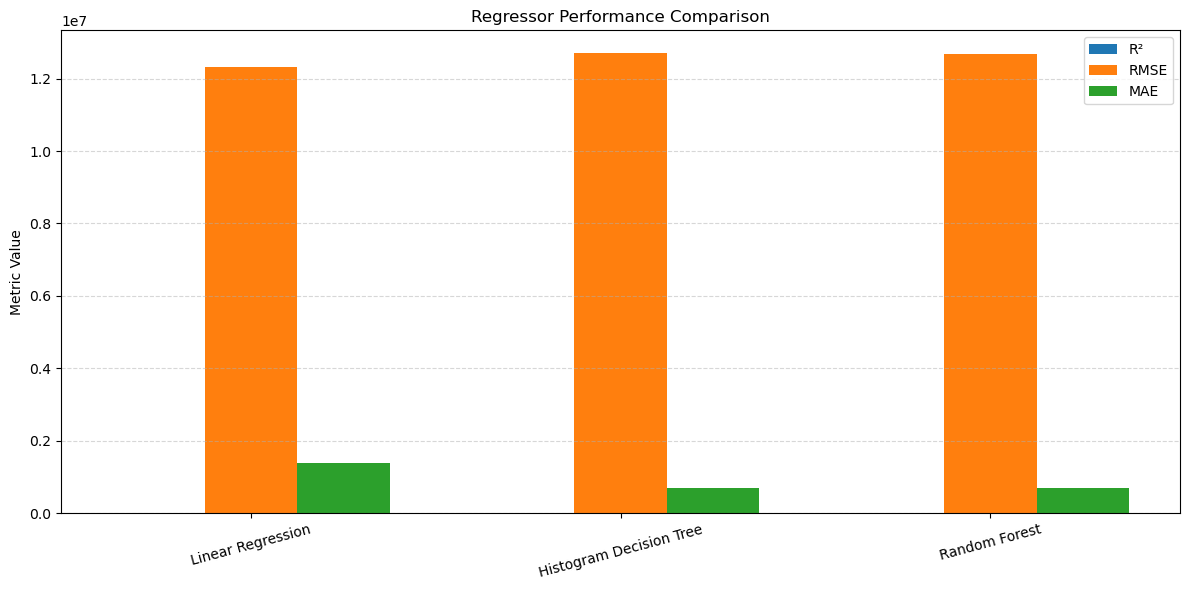

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Metrics
# -------------------------------
def MAE(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def RMSE(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def R2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot


# ==============================================================
# 1. COLLECT RESULTS FOR ALL REGRESSORS
# ==============================================================

results = {}

# ---- Linear Regression ----
results["Linear Regression"] = {
    "R2"   : R2(y_train_np, pred_lr),
    "RMSE" : RMSE(y_train_np, pred_lr),
    "MAE"  : MAE(y_train_np, pred_lr)
}

# ---- Decision Tree ----
results["Histogram Decision Tree"] = {
    "R2"   : R2(y_test_full, preds),
    "RMSE" : RMSE(y_test_full, preds),
    "MAE"  : MAE(y_test_full, preds)
}

# ---- Random Forest ----
results["Random Forest"] = {
    "R2"   : R2(y_test, preds_test),
    "RMSE" : RMSE(y_test, preds_test),
    "MAE"  : MAE(y_test, preds_test)
}

print("=== METRIC TABLE ===")
for model, metrics in results.items():
    print(f"\n{model}:")
    for m, v in metrics.items():
        print(f"  {m}: {v:.4f}")


# ==============================================================
# 2. PLOTTING ALL METRICS
# ==============================================================

models = list(results.keys())
R2_vals   = [results[m]['R2']   for m in models]
RMSE_vals = [results[m]['RMSE'] for m in models]
MAE_vals  = [results[m]['MAE']  for m in models]

x = np.arange(len(models))
w = 0.25

plt.figure(figsize=(12,6))
plt.bar(x - w, R2_vals,   width=w, label="R²")
plt.bar(x,     RMSE_vals, width=w, label="RMSE")
plt.bar(x + w, MAE_vals,  width=w, label="MAE")

plt.xticks(x, models, rotation=15)
plt.title("Regressor Performance Comparison")
plt.ylabel("Metric Value")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



=== Fold 1/5 | train 354113 val 88529 ===
 LR done in 0.62s  R2=0.6737
 Tree done in 91.69s  R2=0.6787
 RF done in 277.75s  R2=0.6787

=== Fold 2/5 | train 354113 val 88529 ===
 LR done in 0.58s  R2=0.7095
 Tree done in 88.21s  R2=0.7185
 RF done in 267.13s  R2=0.7185

=== Fold 3/5 | train 354114 val 88528 ===
 LR done in 0.29s  R2=0.7048
 Tree done in 87.35s  R2=0.7276
 RF done in 262.33s  R2=0.7276

=== Fold 4/5 | train 354114 val 88528 ===
 LR done in 0.43s  R2=0.7081
 Tree done in 87.59s  R2=0.7016
 RF done in 1166.78s  R2=0.7016

=== Fold 5/5 | train 354114 val 88528 ===
 LR done in 0.76s  R2=0.7107
 Tree done in 94.32s  R2=0.6330
 RF done in 295.05s  R2=0.6330

Total CV time: 2727.4s

Per-fold metrics:
               model  fold        R2        RMSE           MAE       time_s
0   LinearRegression     1  0.673651  15445834.0  1.496634e+06     0.622234
1      HistogramTree     1  0.678668  15326643.0  9.492399e+05    91.687935
2       RandomForest     1  0.678668  15326643.0  9.4

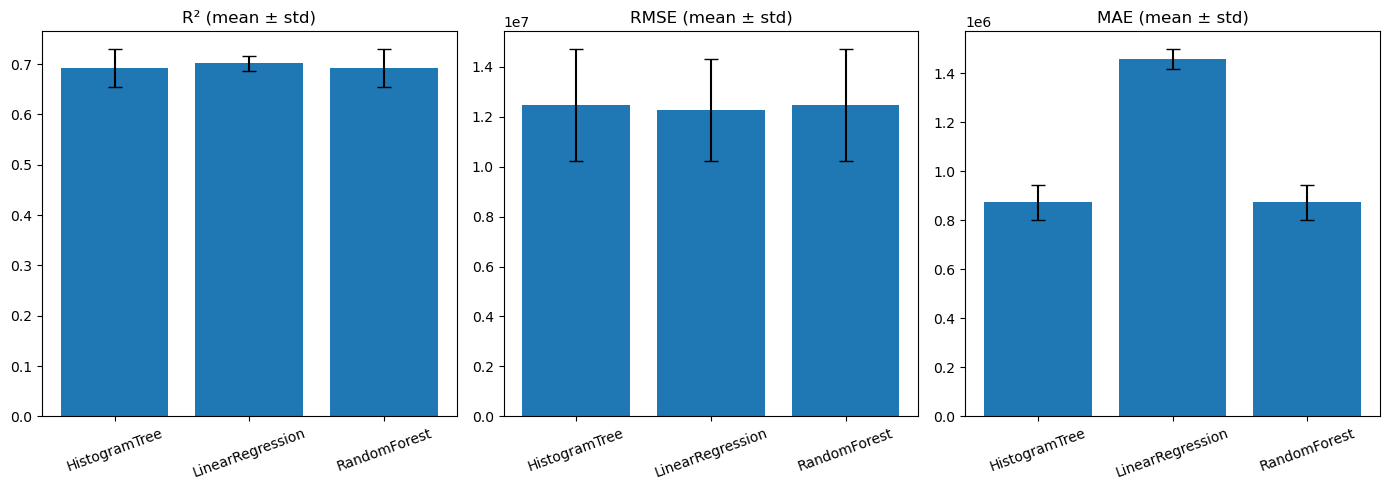

In [ ]:
# ---------- K-Fold CV for three regressors  ----------
import numpy as np
import pandas as pd
import time

def rmse(y, p): return np.sqrt(np.mean((y - p)**2))
def mae(y, p):  return np.mean(np.abs(y - p))
def r2(y, p):
    ss_res = np.sum((y - p)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res / (ss_tot + 1e-12)

def ridge_closed_form(X, y, alpha=1e-6):
    """
    Very fast closed-form ridge solution: w = (X^T X + alpha I)^{-1} X^T y
    Returns w (d,) and b scalar (fit with column of ones).
    """
    n, d = X.shape
    # augment with bias
    X1 = np.hstack([X, np.ones((n,1), dtype=X.dtype)])
    # compute (X1^T X1 + reg)
    A = X1.T @ X1
    # small regularization for numeric stability (do not regularize bias)
    A[:-1, :-1] += alpha * np.eye(d, dtype=A.dtype)
    rhs = X1.T @ y
    sol = np.linalg.solve(A, rhs)   # shape (d+1,)
    w = sol[:-1]
    b = float(sol[-1])
    return w, b

def predict_ridge(X, w, b):
    return X @ w + b

def kfold_indices(n, k=5, seed=42):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    folds = np.array_split(perm, k)
    return folds

def cross_validate_all(X, y, k=5, seed=42, rf_trees=10, tree_bins=128, tree_depth=6, rf_verbose=False):
    """
    X: numpy array (n,d)
    y: numpy array (n,)
    returns: DataFrame with per-fold metrics and aggregated means/stds
    """
    n, d = X.shape
    folds = kfold_indices(n, k=k, seed=seed)

    # storage
    records = []

    for fold_idx in range(k):
        # build train/val indices
        val_idx = folds[fold_idx]
        train_idx = np.hstack([folds[i] for i in range(k) if i != fold_idx])
        X_tr = X[train_idx]
        y_tr = y[train_idx]
        X_val = X[val_idx]
        y_val = y[val_idx]

        print(f"\n=== Fold {fold_idx+1}/{k} | train {X_tr.shape[0]} val {X_val.shape[0]} ===")

        # ---------------- Linear Regression (ridge closed-form) ----------------
        t0 = time.time()
        w, b = ridge_closed_form(X_tr, y_tr, alpha=1e-6)
        pred_val_lr = predict_ridge(X_val, w, b)
        t_lr = time.time() - t0

        lr_metrics = {
            "model":"LinearRegression",
            "fold": fold_idx+1,
            "R2": r2(y_val, pred_val_lr),
            "RMSE": rmse(y_val, pred_val_lr),
            "MAE": mae(y_val, pred_val_lr),
            "time_s": t_lr
        }
        print(f" LR done in {t_lr:.2f}s  R2={lr_metrics['R2']:.4f}")

        records.append(lr_metrics)

        # ---------------- Histogram Decision Tree ----------------
        t0 = time.time()
        tree = HistogramDecisionTreeRegressorFull(
            max_depth=tree_depth,
            min_samples_split=50,
            num_bins=tree_bins,
            sample_features=1.0,
            verbose=False
        )

        tree.fit(X_tr.astype(np.float32), y_tr.astype(np.float32))
        pred_val_tree = tree.predict(X_val.astype(np.float32))
        t_tree = time.time() - t0

        tree_metrics = {
            "model":"HistogramTree",
            "fold": fold_idx+1,
            "R2": r2(y_val, pred_val_tree),
            "RMSE": rmse(y_val, pred_val_tree),
            "MAE": mae(y_val, pred_val_tree),
            "time_s": t_tree
        }
        print(f" Tree done in {t_tree:.2f}s  R2={tree_metrics['R2']:.4f}")

        records.append(tree_metrics)

        # ---------------- Random Forest (use full features & full rows per tree) ----------------
        t0 = time.time()
        # configure RF to use all features and rows per tree (no internal subsampling)
        rf = RandomForestHistogramRegressor(
            n_trees=3,
            max_depth=tree_depth,
            min_samples_split=50,
            num_bins=tree_bins,
            row_sample_ratio=0.7,       # use full rows
            feature_sample_ratio=0.5,   # use all features
            bootstrap=True,            # deterministic full-data trees across folds
            verbose=rf_verbose,
            random_state=seed + fold_idx
        )
        rf.fit(X_tr.astype(np.float32), y_tr.astype(np.float32))
        pred_val_rf = rf.predict(X_val.astype(np.float32))
        t_rf = time.time() - t0

        rf_metrics = {
            "model":"RandomForest",
            "fold": fold_idx+1,
            "R2": r2(y_val, pred_val_rf),
            "RMSE": rmse(y_val, pred_val_rf),
            "MAE": mae(y_val, pred_val_rf),
            "time_s": t_rf
        }
        print(f" RF done in {t_rf:.2f}s  R2={rf_metrics['R2']:.4f}")

        records.append(rf_metrics)

    # assemble DataFrame
    df = pd.DataFrame.from_records(records)
    # aggregate
    agg = df.groupby("model")[["R2","RMSE","MAE","time_s"]].agg(["mean","std"]).round(6)
    return df, agg

# -------------------- RUN 5-fold CV (adjust k or rf_trees if you want) --------------------
k = 5
start_all = time.time()
df_folds, df_agg = cross_validate_all(X_train_np.astype(np.float32), y_train_np.astype(np.float32),
                                      k=k,
                                      seed=42,
                                      rf_trees=10,       # modest trees for CV speed; change if you want
                                      tree_bins=128,
                                      tree_depth=6,
                                      rf_verbose=False)
total_time = time.time() - start_all
print(f"\nTotal CV time: {total_time:.1f}s")

print("\nPer-fold metrics:")
print(df_folds)

print("\nAggregated (mean ± std) across folds:")
print(df_agg)

# -------------- Quick plots: per-model mean ± std for R2 / RMSE / MAE --------------
import matplotlib.pyplot as plt

models = df_agg.index.tolist()
r2_mean = df_agg[("R2","mean")].values
r2_std  = df_agg[("R2","std")].values
rmse_mean = df_agg[("RMSE","mean")].values
rmse_std  = df_agg[("RMSE","std")].values
mae_mean = df_agg[("MAE","mean")].values
mae_std  = df_agg[("MAE","std")].values

x = np.arange(len(models))
w = 0.25

plt.figure(figsize=(14,5))
plt.subplot(1,3,1)
plt.bar(x, r2_mean, yerr=r2_std, capsize=5)
plt.xticks(x, models, rotation=20)
plt.title("R² (mean ± std)")

plt.subplot(1,3,2)
plt.bar(x, rmse_mean, yerr=rmse_std, capsize=5)
plt.xticks(x, models, rotation=20)
plt.title("RMSE (mean ± std)")

plt.subplot(1,3,3)
plt.bar(x, mae_mean, yerr=mae_std, capsize=5)
plt.xticks(x, models, rotation=20)
plt.title("MAE (mean ± std)")

plt.tight_layout()
plt.show()



=== Fold 1/5 | train 354113 val 88529 ===
 LR done in 0.87s  R2=0.6737
 Tree done in 88.33s  R2=0.6787
 RF done in 344.00s  R2=0.5658

=== Fold 2/5 | train 354113 val 88529 ===
 LR done in 0.29s  R2=0.7095
 Tree done in 110.62s  R2=0.7185
 RF done in 348.04s  R2=0.6938

=== Fold 3/5 | train 354114 val 88528 ===
 LR done in 0.52s  R2=0.7048
 Tree done in 88.93s  R2=0.7276
 RF done in 343.24s  R2=0.6883

=== Fold 4/5 | train 354114 val 88528 ===
 LR done in 0.46s  R2=0.7081
 Tree done in 92.18s  R2=0.7016
 RF done in 351.60s  R2=0.6627

=== Fold 5/5 | train 354114 val 88528 ===
 LR done in 0.32s  R2=0.7107
 Tree done in 90.40s  R2=0.6330
 RF done in 353.19s  R2=0.6544

Total CV time: 2219.3s

Per-fold metrics:
               model  fold        R2        RMSE           MAE      time_s
0   LinearRegression     1  0.673651  15445834.0  1.496634e+06    0.871650
1      HistogramTree     1  0.678668  15326643.0  9.492399e+05   88.328581
2       RandomForest     1  0.565826  17815668.0  1.2679

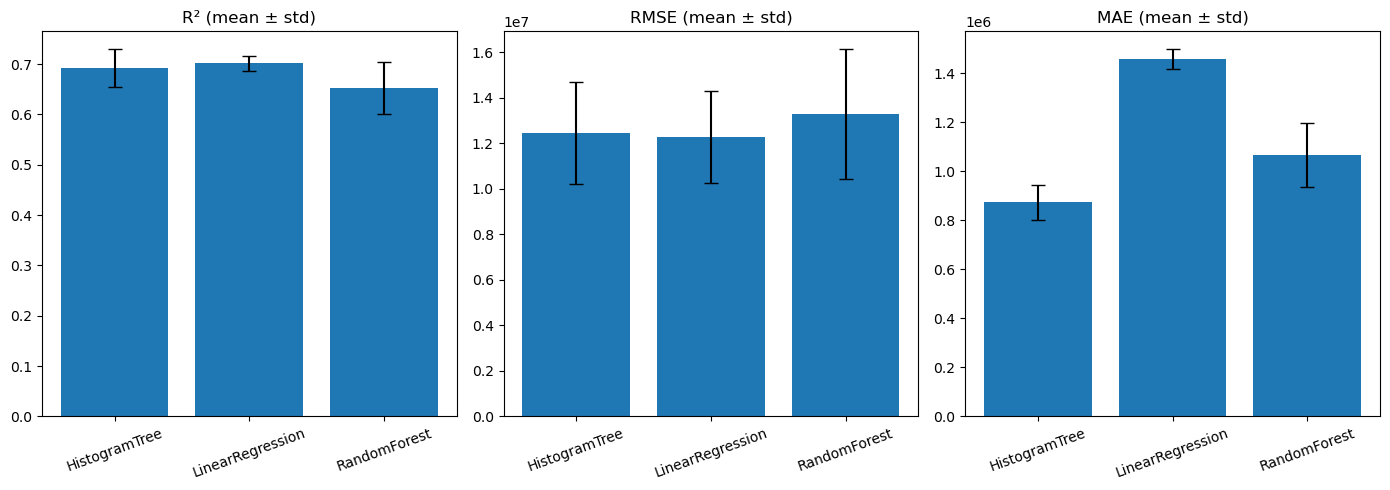

In [34]:
# ---------- K-Fold CV for three regressors (no sklearn) ----------
import numpy as np
import pandas as pd
import time

def rmse(y, p): return np.sqrt(np.mean((y - p)**2))
def mae(y, p):  return np.mean(np.abs(y - p))
def r2(y, p):
    ss_res = np.sum((y - p)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res / (ss_tot + 1e-12)

def ridge_closed_form(X, y, alpha=1e-6):
    """
    Very fast closed-form ridge solution: w = (X^T X + alpha I)^{-1} X^T y
    Returns w (d,) and b scalar (fit with column of ones).
    """
    n, d = X.shape
    # augment with bias
    X1 = np.hstack([X, np.ones((n,1), dtype=X.dtype)])
    # compute (X1^T X1 + reg)
    A = X1.T @ X1
    # small regularization for numeric stability (do not regularize bias)
    A[:-1, :-1] += alpha * np.eye(d, dtype=A.dtype)
    rhs = X1.T @ y
    sol = np.linalg.solve(A, rhs)   # shape (d+1,)
    w = sol[:-1]
    b = float(sol[-1])
    return w, b

def predict_ridge(X, w, b):
    return X @ w + b

def kfold_indices(n, k=5, seed=42):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    folds = np.array_split(perm, k)
    return folds

def cross_validate_all(X, y, k=5, seed=42, rf_trees=10, tree_bins=128, tree_depth=6, rf_verbose=False):
    """
    X: numpy array (n,d)
    y: numpy array (n,)
    returns: DataFrame with per-fold metrics and aggregated means/stds
    """
    n, d = X.shape
    folds = kfold_indices(n, k=k, seed=seed)

    # storage
    records = []

    for fold_idx in range(k):
        # build train/val indices
        val_idx = folds[fold_idx]
        train_idx = np.hstack([folds[i] for i in range(k) if i != fold_idx])
        X_tr = X[train_idx]
        y_tr = y[train_idx]
        X_val = X[val_idx]
        y_val = y[val_idx]

        print(f"\n=== Fold {fold_idx+1}/{k} | train {X_tr.shape[0]} val {X_val.shape[0]} ===")

        # ---------------- Linear Regression (ridge closed-form) ----------------
        t0 = time.time()
        w, b = ridge_closed_form(X_tr, y_tr, alpha=1e-6)
        pred_val_lr = predict_ridge(X_val, w, b)
        t_lr = time.time() - t0

        lr_metrics = {
            "model":"LinearRegression",
            "fold": fold_idx+1,
            "R2": r2(y_val, pred_val_lr),
            "RMSE": rmse(y_val, pred_val_lr),
            "MAE": mae(y_val, pred_val_lr),
            "time_s": t_lr
        }
        print(f" LR done in {t_lr:.2f}s  R2={lr_metrics['R2']:.4f}")

        records.append(lr_metrics)

        # ---------------- Histogram Decision Tree ----------------
        t0 = time.time()
        tree = HistogramDecisionTreeRegressorFull(
            max_depth=tree_depth,
            min_samples_split=50,
            num_bins=tree_bins,
            sample_features=1.0,
            verbose=False
        )

        tree.fit(X_tr.astype(np.float32), y_tr.astype(np.float32))
        pred_val_tree = tree.predict(X_val.astype(np.float32))
        t_tree = time.time() - t0

        tree_metrics = {
            "model":"HistogramTree",
            "fold": fold_idx+1,
            "R2": r2(y_val, pred_val_tree),
            "RMSE": rmse(y_val, pred_val_tree),
            "MAE": mae(y_val, pred_val_tree),
            "time_s": t_tree
        }
        print(f" Tree done in {t_tree:.2f}s  R2={tree_metrics['R2']:.4f}")

        records.append(tree_metrics)

        # ---------------- Random Forest (use full features & full rows per tree) ----------------
        t0 = time.time()
        # configure RF to use all features and rows per tree (no internal subsampling)
        rf = RandomForestHistogramRegressor(
            n_trees=10,
            max_depth=tree_depth,
            min_samples_split=50,
            num_bins=tree_bins,
            row_sample_ratio=0.7,       # use full rows
            feature_sample_ratio=0.5,   # use all features
            bootstrap=True,            # deterministic full-data trees across folds
            verbose=rf_verbose,
            random_state=seed + fold_idx
        )
        rf.fit(X_tr.astype(np.float32), y_tr.astype(np.float32))
        pred_val_rf = rf.predict(X_val.astype(np.float32))
        t_rf = time.time() - t0

        rf_metrics = {
            "model":"RandomForest",
            "fold": fold_idx+1,
            "R2": r2(y_val, pred_val_rf),
            "RMSE": rmse(y_val, pred_val_rf),
            "MAE": mae(y_val, pred_val_rf),
            "time_s": t_rf
        }
        print(f" RF done in {t_rf:.2f}s  R2={rf_metrics['R2']:.4f}")

        records.append(rf_metrics)

    # assemble DataFrame
    df = pd.DataFrame.from_records(records)
    # aggregate
    agg = df.groupby("model")[["R2","RMSE","MAE","time_s"]].agg(["mean","std"]).round(6)
    return df, agg

# -------------------- RUN 5-fold CV (adjust k or rf_trees if you want) --------------------
k = 5
start_all = time.time()
df_folds, df_agg = cross_validate_all(X_train_np.astype(np.float32), y_train_np.astype(np.float32),
                                      k=k,
                                      seed=42,
                                      rf_trees=10,       # modest trees for CV speed; change if you want
                                      tree_bins=128,
                                      tree_depth=6,
                                      rf_verbose=False)
total_time = time.time() - start_all
print(f"\nTotal CV time: {total_time:.1f}s")

print("\nPer-fold metrics:")
print(df_folds)

print("\nAggregated (mean ± std) across folds:")
print(df_agg)

# -------------- Quick plots: per-model mean ± std for R2 / RMSE / MAE --------------
import matplotlib.pyplot as plt

models = df_agg.index.tolist()
r2_mean = df_agg[("R2","mean")].values
r2_std  = df_agg[("R2","std")].values
rmse_mean = df_agg[("RMSE","mean")].values
rmse_std  = df_agg[("RMSE","std")].values
mae_mean = df_agg[("MAE","mean")].values
mae_std  = df_agg[("MAE","std")].values

x = np.arange(len(models))
w = 0.25

plt.figure(figsize=(14,5))
plt.subplot(1,3,1)
plt.bar(x, r2_mean, yerr=r2_std, capsize=5)
plt.xticks(x, models, rotation=20)
plt.title("R² (mean ± std)")

plt.subplot(1,3,2)
plt.bar(x, rmse_mean, yerr=rmse_std, capsize=5)
plt.xticks(x, models, rotation=20)
plt.title("RMSE (mean ± std)")

plt.subplot(1,3,3)
plt.bar(x, mae_mean, yerr=mae_std, capsize=5)
plt.xticks(x, models, rotation=20)
plt.title("MAE (mean ± std)")

plt.tight_layout()
plt.show()


**clasifiers**

In [ ]:
# Instantiate model
num_classes = len(genre_list)
logreg = LogisticRegressionScratch(lr=0.05, epochs=200)

# Train
print("\nTraining Logistic Regression Classifier...")
logreg.fit(X_train_np, y_genre_train.to_numpy())
print("Training complete.")

# Predict on train and test
y_pred_train = logreg.predict(X_train_np)
y_pred_test  = logreg.predict(X_test_np)

# -------------------------
# Evaluation metrics
# -------------------------
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def precision_recall_f1(y_true, y_pred, num_classes):
    precision = np.zeros(num_classes)
    recall = np.zeros(num_classes)
    f1 = np.zeros(num_classes)
    
    for c in range(num_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        
        precision[c] = tp / (tp + fp + 1e-8)
        recall[c]    = tp / (tp + fn + 1e-8)
        f1[c]        = 2 * precision[c] * recall[c] / (precision[c] + recall[c] + 1e-8)
    
    return precision, recall, f1

# Accuracy
acc_train = accuracy(y_genre_train.to_numpy(), y_pred_train)
acc_test  = accuracy(y_genre_test.to_numpy(), y_pred_test)

# Precision, recall, F1
precision, recall, f1 = precision_recall_f1(y_genre_test.to_numpy(), y_pred_test, num_classes)

print("\n===== Logistic Regression Evaluation =====")
print(f"Train Accuracy: {acc_train:.4f}")
print(f"Test Accuracy : {acc_test:.4f}")
print(f"Precision (per class): {precision}")
print(f"Recall (per class)   : {recall}")
print(f"F1-score (per class) : {f1}")
print("==========================================")



Training Logistic Regression Classifier...
Epoch 20/200 → Loss: 2.8718
Epoch 40/200 → Loss: 2.7568
Epoch 60/200 → Loss: 2.6583
Epoch 80/200 → Loss: 2.5761
Epoch 100/200 → Loss: 2.5089
Epoch 120/200 → Loss: 2.4546
Epoch 140/200 → Loss: 2.4109
Epoch 160/200 → Loss: 2.3757
Epoch 180/200 → Loss: 2.3469
Epoch 200/200 → Loss: 2.3231
Training complete.

===== Logistic Regression Evaluation =====
Train Accuracy: 0.3290
Test Accuracy : 0.3278
Precision (per class): [0.37856027 0.         0.26339286 0.         0.         0.2234805
 0.         0.24300977 0.         0.         0.         0.25409836
 0.         0.         0.         0.         0.         0.
 0.         0.        ]
Recall (per class)   : [0.86649021 0.         0.01234826 0.         0.         0.34783644
 0.         0.09727467 0.         0.         0.         0.00393951
 0.         0.         0.         0.         0.         0.
 0.         0.        ]
F1-score (per class) : [0.52691641 0.         0.02359056 0.         0.         0.2

In [23]:
import numpy as np

class DecisionTreeClassifierScratch:
    def __init__(self, max_depth=6, min_samples_split=50, 
                 sample_rows=50000, num_thresholds=20):
        
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.sample_rows = sample_rows
        self.num_thresholds = num_thresholds
        self.tree = None

    # ---------------------
    # Gini impurity
    # ---------------------
    def gini(self, y):
        classes, counts = np.unique(y, return_counts=True)
        probs = counts / counts.sum()
        return 1 - np.sum(probs ** 2)

    # ---------------------
    # Best split
    # ---------------------
    def best_split(self, X, y):
        n, d = X.shape
        best_feat, best_thresh, best_gini = None, None, float("inf")

        for feature in range(d):
            thresholds = np.quantile(
                X[:, feature], np.linspace(0.05, 0.95, self.num_thresholds)
            )
            for t in thresholds:
                left_mask = X[:, feature] <= t
                right_mask = ~left_mask
                if left_mask.sum() < self.min_samples_split or right_mask.sum() < self.min_samples_split:
                    continue
                gini_split = (len(left_mask)*self.gini(y[left_mask]) + 
                              len(right_mask)*self.gini(y[right_mask])) / n
                if gini_split < best_gini:
                    best_feat = feature
                    best_thresh = t
                    best_gini = gini_split

        return best_feat, best_thresh

    # ---------------------
    # Build tree recursively
    # ---------------------
    def build_tree(self, X, y, depth):
        if depth >= self.max_depth or len(y) < self.min_samples_split:
            # Leaf: return majority class
            classes, counts = np.unique(y, return_counts=True)
            return classes[np.argmax(counts)]

        feat, thresh = self.best_split(X, y)
        if feat is None:
            classes, counts = np.unique(y, return_counts=True)
            return classes[np.argmax(counts)]

        left_mask = X[:, feat] <= thresh
        right_mask = ~left_mask
        node = {
            "feature": feat,
            "threshold": thresh,
            "left": self.build_tree(X[left_mask], y[left_mask], depth + 1),
            "right": self.build_tree(X[right_mask], y[right_mask], depth + 1)
        }
        return node

    # ---------------------
    # Fit
    # ---------------------
    def fit(self, X, y):
        if len(X) > self.sample_rows:
            idx = np.random.choice(len(X), self.sample_rows, replace=False)
            X = X[idx]
            y = y[idx]
        self.tree = self.build_tree(X, y, depth=0)
        print("Decision Tree Classifier trained.")

    # ---------------------
    # Predict one row
    # ---------------------
    def predict_one(self, x, node):
        while isinstance(node, dict):
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node

    # ---------------------
    # Predict all
    # ---------------------
    def predict(self, X):
        return np.array([self.predict_one(row, self.tree) for row in X])


In [24]:
class RandomForestClassifierScratch:
    def __init__(self, n_trees=5, max_depth=6, min_samples_split=50, 
                 row_sample_ratio=0.6, feature_sample_ratio=0.5, num_thresholds=20):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.row_sample_ratio = row_sample_ratio
        self.feature_sample_ratio = feature_sample_ratio
        self.num_thresholds = num_thresholds
        self.trees = []
        self.feature_indices_list = []

    # -------------------------
    # Fit forest
    # -------------------------
    def fit(self, X, y):
        n_samples, n_features = X.shape
        for t in range(self.n_trees):
            # Row bootstrap
            row_idx = np.random.choice(n_samples, int(self.row_sample_ratio*n_samples), replace=True)
            X_sub, y_sub = X[row_idx], y[row_idx]

            # Random feature subset
            feat_idx = np.random.choice(n_features, int(self.feature_sample_ratio*n_features), replace=False)
            self.feature_indices_list.append(feat_idx)

            tree = DecisionTreeClassifierScratch(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                sample_rows=50000,
                num_thresholds=self.num_thresholds
            )
            tree.fit(X_sub[:, feat_idx], y_sub)
            self.trees.append(tree)

        print("Random Forest Classifier trained.")

    # -------------------------
    # Predict
    # -------------------------
    def predict(self, X):
        all_preds = []
        for t, tree in enumerate(self.trees):
            feat_idx = self.feature_indices_list[t]
            preds = tree.predict(X[:, feat_idx])
            all_preds.append(preds)
        all_preds = np.array(all_preds)
        # Majority vote
        final_preds = []
        for i in range(X.shape[0]):
            counts = np.bincount(all_preds[:, i])
            final_preds.append(np.argmax(counts))
        return np.array(final_preds)


In [26]:
import numpy as np

def precision_per_class(y_true, y_pred, n_classes):
    precision = []
    for cls in range(n_classes):
        tp = np.sum((y_pred == cls) & (y_true == cls))
        fp = np.sum((y_pred == cls) & (y_true != cls))
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        precision.append(prec)
    return np.array(precision)

def recall_per_class(y_true, y_pred, n_classes):
    recall = []
    for cls in range(n_classes):
        tp = np.sum((y_pred == cls) & (y_true == cls))
        fn = np.sum((y_pred != cls) & (y_true == cls))
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0
        recall.append(rec)
    return np.array(recall)

def f1_per_class(y_true, y_pred, n_classes):
    prec = precision_per_class(y_true, y_pred, n_classes)
    rec = recall_per_class(y_true, y_pred, n_classes)
    f1 = np.zeros_like(prec)
    for i in range(n_classes):
        f1[i] = 2 * prec[i] * rec[i] / (prec[i] + rec[i]) if (prec[i] + rec[i]) > 0 else 0
    return f1

def overall_accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


In [29]:
# Number of classes
n_classes = len(np.unique(y_genre_train))

# Decision Tree
dt_final = DecisionTreeClassifierScratch(max_depth=6, min_samples_split=50)
dt_final.fit(X_train_np, y_genre_train.to_numpy())
y_pred_dt_final = dt_final.predict(X_test_np)
print("Final Decision Tree Accuracy:", overall_accuracy(y_genre_test.to_numpy(), y_pred_dt_final))

# Random Forest
rf_final = RandomForestClassifierScratch(n_trees=10, max_depth=6)
rf_final.fit(X_train_np, y_genre_train.to_numpy())
y_pred_rf_final = rf_final.predict(X_test_np)
print("Final Random Forest Accuracy:", overall_accuracy(y_genre_test.to_numpy(), y_pred_rf_final))


Decision Tree Classifier trained.
Final Decision Tree Accuracy: 0.30183990475135675
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Decision Tree Classifier trained.
Random Forest Classifier trained.
Final Random Forest Accuracy: 0.3056886144645033


In [38]:
import numpy as np

def run_k_fold_cv_logreg(X, y, k=5, lr=0.01, epochs=200):
    """
    K-Fold Cross Validation for Logistic Regression (your existing class)
    Returns results dictionary with metrics per fold
    """
    n_samples = len(X)
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    # Compute fold sizes
    fold_sizes = np.full(k, n_samples // k)
    fold_sizes[:n_samples % k] += 1
    
    current = 0
    folds = []
    for size in fold_sizes:
        start, stop = current, current + size
        folds.append(indices[start:stop])
        current = stop
    
    results = {
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1": []
    }
    
    n_classes = len(np.unique(y))
    
    for fold_idx in range(k):
        val_idx = folds[fold_idx]
        train_idx = np.hstack([folds[i] for i in range(k) if i != fold_idx])
        
        X_train, y_train = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]
        
        # ---------------- Train Logistic Regression ----------------
        logreg = LogisticRegressionScratch(lr=lr, epochs=epochs)
        logreg.fit(X_train, y_train)
        y_pred = logreg.predict(X_val)
        
        # ---------------- Compute Metrics ----------------
        results["Accuracy"].append(overall_accuracy(y_val, y_pred))
        results["Precision"].append(precision_per_class(y_val, y_pred, n_classes))
        results["Recall"].append(recall_per_class(y_val, y_pred, n_classes))
        results["F1"].append(f1_per_class(y_val, y_pred, n_classes))
        
        print(f"Fold {fold_idx+1} → Accuracy: {results['Accuracy'][-1]:.4f}")
    
    return results


In [39]:
def run_k_fold_cv_all_classifiers(X, y, n_classes, k=5, 
                                  lr=0.01, epochs=200,
                                  dt_max_depth=6, dt_min_samples=50,
                                  rf_n_trees=5, rf_max_depth=6):
    
    n_samples = len(X)
    folds = k_fold_indices(n_samples, k)
    
    results = {
        "LogisticRegression": {"Accuracy": [], "Precision": [], "Recall": [], "F1": []},
        "DecisionTree": {"Accuracy": [], "Precision": [], "Recall": [], "F1": []},
        "RandomForest": {"Accuracy": [], "Precision": [], "Recall": [], "F1": []}
    }
    
    for fold_idx in range(k):
        print(f"\n================ Fold {fold_idx+1}/{k} ================\n")
        val_idx = folds[fold_idx]
        train_idx = np.hstack([folds[j] for j in range(k) if j != fold_idx])
        
        X_train, y_train = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]
        
        # ---------------- Logistic Regression ----------------
        logreg = LogisticRegressionScratch(lr=lr, epochs=epochs, n_classes=n_classes)
        logreg.fit(X_train, y_train)
        y_pred_logreg = logreg.predict(X_val)
        
        results["LogisticRegression"]["Accuracy"].append(overall_accuracy(y_val, y_pred_logreg))
        results["LogisticRegression"]["Precision"].append(precision_per_class(y_val, y_pred_logreg, n_classes))
        results["LogisticRegression"]["Recall"].append(recall_per_class(y_val, y_pred_logreg, n_classes))
        results["LogisticRegression"]["F1"].append(f1_per_class(y_val, y_pred_logreg, n_classes))
        
        print(f"Logistic Regression → Acc: {results['LogisticRegression']['Accuracy'][-1]:.4f}")
        
        # ---------------- Decision Tree ----------------
        dt = DecisionTreeClassifierScratch(max_depth=dt_max_depth, min_samples_split=dt_min_samples)
        dt.fit(X_train, y_train)
        y_pred_dt = dt.predict(X_val)
        
        results["DecisionTree"]["Accuracy"].append(overall_accuracy(y_val, y_pred_dt))
        results["DecisionTree"]["Precision"].append(precision_per_class(y_val, y_pred_dt, n_classes))
        results["DecisionTree"]["Recall"].append(recall_per_class(y_val, y_pred_dt, n_classes))
        results["DecisionTree"]["F1"].append(f1_per_class(y_val, y_pred_dt, n_classes))
        
        print(f"Decision Tree → Acc: {results['DecisionTree']['Accuracy'][-1]:.4f}")
        
        # ---------------- Random Forest ----------------
        rf = RandomForestClassifierScratch(n_trees=rf_n_trees, max_depth=rf_max_depth)
        rf.fit(X_train, y_train)
        y_pred_rf = rf.predict(X_val)
        
        results["RandomForest"]["Accuracy"].append(overall_accuracy(y_val, y_pred_rf))
        results["RandomForest"]["Precision"].append(precision_per_class(y_val, y_pred_rf, n_classes))
        results["RandomForest"]["Recall"].append(recall_per_class(y_val, y_pred_rf, n_classes))
        results["RandomForest"]["F1"].append(f1_per_class(y_val, y_pred_rf, n_classes))
        
        print(f"Random Forest → Acc: {results['RandomForest']['Accuracy'][-1]:.4f}")
        
    return results
def summarize_logreg_cv(results, n_classes):
    print("\n===== Logistic Regression 5-Fold CV Summary =====")
    print(f"Accuracy: mean = {np.mean(results['Accuracy']):.4f}, std = {np.std(results['Accuracy']):.4f}")
    
    precision = np.array(results["Precision"])
    recall = np.array(results["Recall"])
    f1 = np.array(results["F1"])
    
    print(f"Precision per class (mean over folds): {np.mean(precision, axis=0)}")
    print(f"Recall per class    (mean over folds): {np.mean(recall, axis=0)}")
    print(f"F1-score per class  (mean over folds): {np.mean(f1, axis=0)}")


In [40]:
# Number of classes
n_classes = len(np.unique(y_genre_train))

# Run 5-Fold CV
logreg_results = run_k_fold_cv_logreg(
    X_train_np,
    y_genre_train.to_numpy(),
    k=5,
    lr=0.01,
    epochs=200
)

# Summarize results
summarize_logreg_cv(logreg_results, n_classes)


Epoch 20/200 → Loss: 2.9699
Epoch 40/200 → Loss: 2.9432
Epoch 60/200 → Loss: 2.9172
Epoch 80/200 → Loss: 2.8918
Epoch 100/200 → Loss: 2.8670
Epoch 120/200 → Loss: 2.8428
Epoch 140/200 → Loss: 2.8193
Epoch 160/200 → Loss: 2.7964
Epoch 180/200 → Loss: 2.7742
Epoch 200/200 → Loss: 2.7526
Fold 1 → Accuracy: 0.3286
Epoch 20/200 → Loss: 2.9699
Epoch 40/200 → Loss: 2.9433
Epoch 60/200 → Loss: 2.9172
Epoch 80/200 → Loss: 2.8918
Epoch 100/200 → Loss: 2.8670
Epoch 120/200 → Loss: 2.8429
Epoch 140/200 → Loss: 2.8194
Epoch 160/200 → Loss: 2.7965
Epoch 180/200 → Loss: 2.7743
Epoch 200/200 → Loss: 2.7528
Fold 2 → Accuracy: 0.3293
Epoch 20/200 → Loss: 2.9699
Epoch 40/200 → Loss: 2.9433
Epoch 60/200 → Loss: 2.9173
Epoch 80/200 → Loss: 2.8919
Epoch 100/200 → Loss: 2.8671
Epoch 120/200 → Loss: 2.8430
Epoch 140/200 → Loss: 2.8195
Epoch 160/200 → Loss: 2.7966
Epoch 180/200 → Loss: 2.7744
Epoch 200/200 → Loss: 2.7529
Fold 3 → Accuracy: 0.3293
Epoch 20/200 → Loss: 2.9700
Epoch 40/200 → Loss: 2.9434
Epoch 60

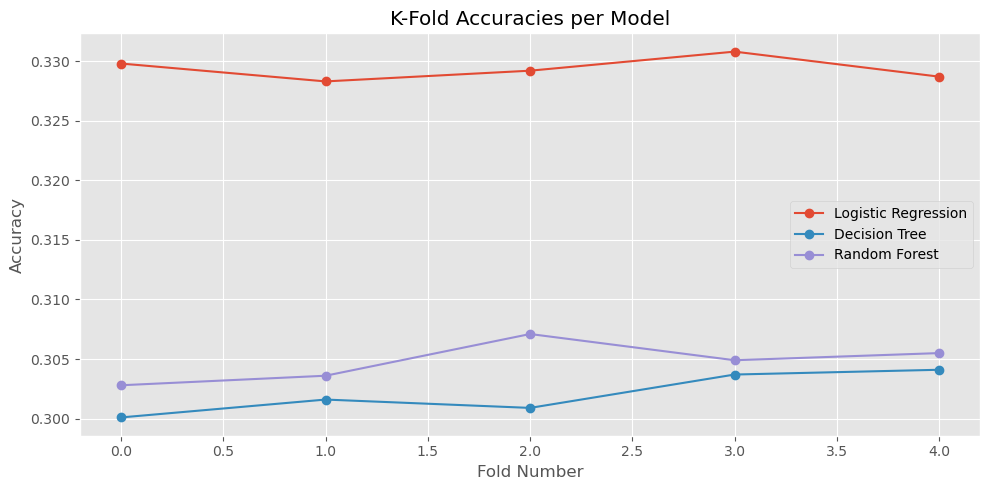

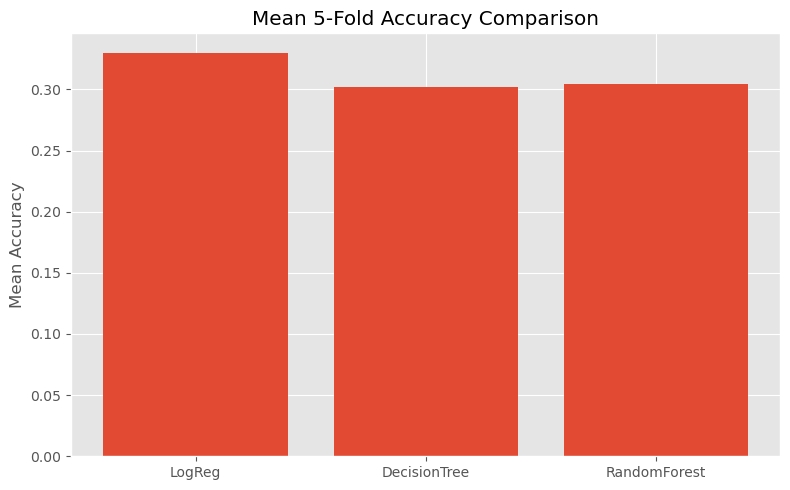

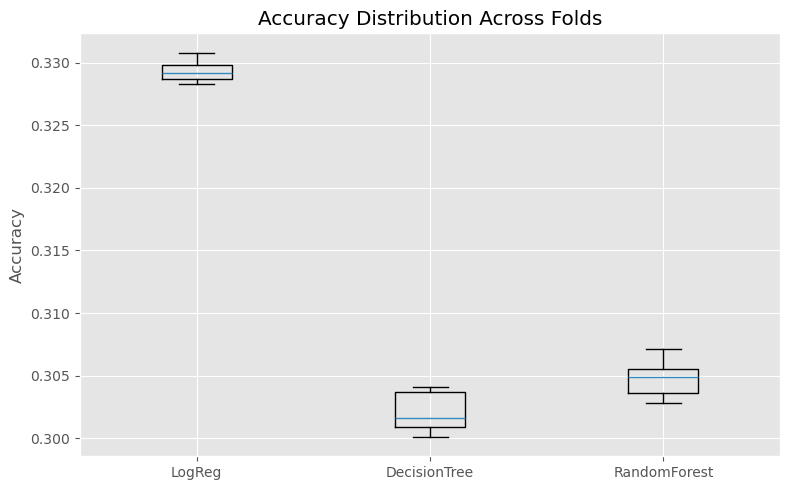

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# K-FOLD RESULTS (insert your computed values)
# ============================================
plt.style.use("ggplot")

logreg_acc = np.array([0.3298, 0.3283, 0.3292, 0.3308, 0.3287])
dt_acc     = np.array([0.3001, 0.3016, 0.3009, 0.3037, 0.3041])
rf_acc     = np.array([0.3028, 0.3036, 0.3071, 0.3049, 0.3055])

# Mean accuracies
logreg_mean = logreg_acc.mean()
dt_mean     = dt_acc.mean()
rf_mean     = rf_acc.mean()

# ============================================
# 1. LINE PLOT — Per-Fold Accuracies
# ============================================

plt.figure(figsize=(10, 5))
plt.plot(logreg_acc, marker='o', label="Logistic Regression")
plt.plot(dt_acc, marker='o', label="Decision Tree")
plt.plot(rf_acc, marker='o', label="Random Forest")

plt.title("K-Fold Accuracies per Model")
plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================
# 2. BAR PLOT — Mean Accuracy Comparison
# ============================================

plt.figure(figsize=(8, 5))
models = ["LogReg", "DecisionTree", "RandomForest"]
means = [logreg_mean, dt_mean, rf_mean]

plt.bar(models, means)
plt.title("Mean 5-Fold Accuracy Comparison")
plt.ylabel("Mean Accuracy")
plt.tight_layout()
plt.show()

# ============================================
# 3. BOXPLOT — Accuracy Distribution
# ============================================

plt.figure(figsize=(8, 5))
plt.boxplot([logreg_acc, dt_acc, rf_acc], labels=models)
plt.title("Accuracy Distribution Across Folds")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()
